<a href="https://colab.research.google.com/github/WendelLeander/PhishEvade/blob/main/Modules/8_model_testing_performance_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Testing and Performance Evaluation
**Study:** Obfuscation-Aware Feature Engineering for Evasion-Heavy Phishing URL Detection

This notebook independently reloads all **15 saved Module 7 models** and the separate Module 6 baseline, verifies their integrity, and evaluates them on the two evaluation sets fixed in the dataset's `split` column:

| Evaluation set | Contents | Role |
|---|---|---|
| `test` | 20 % of the non-holdout rows, class-balanced | Standard hold-out comparison of all 15 combinations against the baseline |
| `evasion_holdout` | Every phishing URL first seen on or after 2026-03-01 (the newest samples, cross-checked against PhishTank / PhishStats dates) plus an equal number of benign URLs | **Evasion-heavy generalization testing**: newer phishing URLs that were excluded from training and tuning |

No fitting, grid search, or threshold selection occurs here. The decision rule is the fixed **P(phishing) ≥ 0.5**. Each model's tuned threshold (training-set Youden's J) is reported separately as an adjustment aid only, for cases where the 0.5 results do not reflect the expected behavior.

**Read before drawing conclusions:** all scaling is fitted **inside each model's pipeline, on the `train` rows only**, so neither evaluation set influenced preprocessing, and the evasion holdout was never used for training, tuning or threshold selection. Modules 6 and 7 displayed test-set scores (the holdout is first scored in Module 6 for the baseline only), so the test results are provisional rather than a newly untouched test. The holdout's phishing side is temporal; its benign side is not (the benign top-site lists carry no collection dates). Results do not establish zero-day detection on independent feeds, domain-disjoint generalization, or causal effects of obfuscation.

The proposal Table 4.1 and current repository define **3 Level 1 + 10 Level 2 = 13** features. The milestone form's six/seven wording conflicts with that definition; this notebook follows the final proposal's explicit feature allocation and Modules 3–7.

**Run:** on Google Colab, run the *Get the repository* cell first (it clones or updates the GitHub repository); locally, run this notebook from `Modules/` or the repository root. Run it after Modules 2–7 (with their outputs pushed), then run Module 9. Module 7 models take **raw** features from `Dataset/Extracted_Features.csv` (they scale internally); the scaled `Dataset/Final_Dataset.csv` is used only to check the Module 6 baseline. Inputs must remain together under `Dataset/`, `Models/`, `Metrics/`, and `Modules/`. Only load trusted joblib files; the model manifest is verified before deserialization.

Dependencies (install in your notebook kernel if needed): `pandas numpy matplotlib scipy psutil joblib nbformat scikit-learn xgboost tldextract threadpoolctl`. Matching training library versions is recommended for persisted models. This notebook records actual runtime versions.

## Get the repository (Colab)
This notebook reads the models, metrics and dataset files from the repository folders. On **Google Colab** the cell below clones the GitHub repository (or pulls the latest commits if it was already cloned in this session) and moves into `Modules/`, so every input comes from the same pushed snapshot. Push the outputs of the previous milestones before running it. When the notebook is run locally inside the repository, the cell does nothing. Outputs are written inside the clone; download them from Colab's file panel (or push them) before the session ends.

In [ ]:
# Get the repository. On Google Colab (stateless) this clones the GitHub repo, or pulls the latest
# commits if it was already cloned in this session, then moves into Modules/. Run locally inside the
# repo, it does nothing. The notebook reads Dataset/, Models/, Metrics/ (and Results/) from the clone.
import os, sys, subprocess
REPO_URL  = "https://github.com/WendelLeander/PhishEvade.git"
REPO_DIR  = "/content/PhishEvade"

def ensure_repo(in_colab=("google.colab" in sys.modules)):
    if not in_colab:
        print("Not running on Colab: using the local repository.")
        return
    if os.path.isdir(os.path.join(REPO_DIR, ".git")):
        subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    os.chdir(os.path.join(REPO_DIR, "Modules"))
    head = subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--format=%h %cd %s", "--date=short"],
                          capture_output=True, text=True).stdout.strip()
    print("Repository ready at", os.getcwd(), "| latest commit:", head)

ensure_repo()

Repository ready at /content/PhishEvade/Modules | latest commit: edace3c 2026-11-10 updated to latest


In [ ]:
# Install the packages Colab does not include by default (safe to re-run; already-installed ones are skipped).
# pandas, numpy, matplotlib, scikit-learn, xgboost, scipy, psutil and joblib are preinstalled on Colab.
%pip install -q tldextract threadpoolctl

In [ ]:
from pathlib import Path
import io, os, sys, json, hashlib, time, platform, warnings, threading, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, xgboost, psutil, scipy, tldextract
from IPython.display import display, Markdown
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import (confusion_matrix, f1_score, accuracy_score, precision_score,
    recall_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    brier_score_loss)
from sklearn.calibration import calibration_curve
from scipy.stats import binomtest
from threadpoolctl import threadpool_limits

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'Dataset/Final_Dataset.csv').is_file() and (p/'Metrics/models_manifest.csv').is_file()), None)
assert ROOT is not None, 'Run inside the PhishEvade repository (root or Modules).'
OUT = ROOT/'Results/milestone8'; OUT.mkdir(parents=True, exist_ok=True)
FIG = OUT/'figures'; FIG.mkdir(exist_ok=True)
SEED=42; THRESHOLD=0.5; N_BOOT=2000; LATENCY_REPEATS=1
SPLITS=['train','test','evasion_holdout']; HOLDOUT_CUTOFF=pd.Timestamp('2026-03-01',tz='UTC')
BENIGN_GROUPS=['domain_only','light_path','obfuscated']
L1=['url_length','domain_length','path_length']
L2=['subdomain_count','path_depth','query_params_count','digit_ratio','special_char_ratio',
    'token_variance','domain_entropy','redirect_key_flag','nested_url_flag','query_encoding_ratio']
FS={'Level 1':L1,'Level 2':L2,'Combined':L1+L2}
CLASSIFIERS=['Logistic Regression','Random Forest','XGBoost','Naive Bayes','AdaBoost']
MM=['url_length','domain_length','path_length','digit_ratio','special_char_ratio','query_encoding_ratio']
ZS=['subdomain_count','path_depth','query_params_count','token_variance','domain_entropy']
thread_limits = threadpool_limits(limits=1)  # keep native thread counts comparable
pd.set_option('display.max_columns',40)
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_table(frame,name):
    frame.to_csv(OUT/(name+'.csv'),index=False)
    return frame

def figure(name):
    plt.tight_layout()
    buf=io.BytesIO()
    plt.savefig(buf,format='png',dpi=150,bbox_inches='tight')
    (FIG/(name+'.png')).write_bytes(buf.getvalue())
    plt.show(); plt.close()
def slug(s):return s.lower().replace(' ','_').replace('+','plus')
def key(c,f):return slug(c)+'__'+slug(f)
print('Repository:',ROOT)
print('Primary threshold:',THRESHOLD,'| bootstrap repetitions:',N_BOOT)

Repository: /content/PhishEvade
Primary threshold: 0.5 | bootstrap repetitions: 2000


## 1. Input, partition, scaling, and artifact audit
Checks fail immediately for missing/mismatched models, rows, labels, features, splits, checksums, or baseline results. The `split` column must agree across every dataset file and the baseline's saved split, and the evasion holdout must be strictly newer than every training and test phishing URL. CSV row positions remain the sample identifiers; URLs are read only as strings and are never visited. The exact data hashes are saved for future reproducibility.

In [ ]:
data=pd.read_csv(ROOT/'Dataset/Final_Dataset.csv')
raw=pd.read_csv(ROOT/'Dataset/Extracted_Features.csv',keep_default_na=False,na_values={'label':['']})
pre=pd.read_csv(ROOT/'Dataset/Preprocessed_Dataset.csv',keep_default_na=False,na_values={'label':['']})
record=json.loads((ROOT/'Metrics/all_models_metrics.json').read_text())
manifest=pd.read_csv(ROOT/'Metrics/models_manifest.csv')
split=pd.read_csv(ROOT/'Models/train_test_split_indices.csv')
assert list(data.columns)==L1+L2+['label','split'], 'Final_Dataset.csv must be the scaling notebook output with a split column'
for col in ['split','date','benign_group']: assert col in raw.columns, f'Extracted_Features.csv has no {col} column'
assert len(data)==len(raw)==len(pre)==len(split)
assert raw.label.equals(data.label) and np.array_equal(pre.label,data.label)
assert raw.url.equals(pre.url), 'URL order differs between raw-feature and preprocessing files.'
assert np.isfinite(data[L1+L2].to_numpy(float)).all() and np.isfinite(raw[L1+L2].to_numpy(float)).all()
assert raw.url.str.len().gt(0).all() and raw.url.is_unique
# one split, everywhere
assert set(raw.split)==set(SPLITS)
assert (raw.split.to_numpy()==data.split.to_numpy()).all() and (raw.split.to_numpy()==pre.split.to_numpy()).all()
assert split.row_index.tolist()==list(range(len(raw))) and (split['split'].to_numpy()==raw.split.to_numpy()).all(), \
    'Models/train_test_split_indices.csv does not match the dataset split: re-run the baseline notebook'
y=raw.label.to_numpy(int)
train_idx=np.flatnonzero(raw.split=='train'); test_idx=np.flatnonzero(raw.split=='test'); holdout_idx=np.flatnonzero(raw.split=='evasion_holdout')
yr=y[train_idx]; yt=y[test_idx]; yh=y[holdout_idx]
for name,yy in [('test',yt),('evasion_holdout',yh)]:
    assert (yy==0).sum()==(yy==1).sum(), f'{name} is not class-balanced'
# temporal design of the evasion holdout
pdate=pd.to_datetime(raw.date.where(raw.label==1),utc=True,errors='coerce')
assert pdate[raw.label==1].notna().all(), 'every phishing URL needs a first-seen date'
assert (pdate.iloc[holdout_idx][yh==1]>=HOLDOUT_CUTOFF).all()
assert (pdate.iloc[np.r_[train_idx,test_idx]][y[np.r_[train_idx,test_idx]]==1]<HOLDOUT_CUTOFF).all()

# Reconstruct Module 5's scaling (fitted on TRAIN rows only) to validate file lineage.
reconstructed=raw[L1+L2].astype(float).copy()
for cols,scaler in [(MM,MinMaxScaler()),(ZS,StandardScaler())]:
    scaler.fit(raw.iloc[train_idx][cols]); reconstructed[cols]=scaler.transform(raw[cols])
assert np.allclose(reconstructed,data[L1+L2],rtol=1e-7,atol=1e-10), 'Final_Dataset.csv was not scaled on the train rows only'
# Diagnostic: how much would the old all-rows scaling have differed on the evaluation rows?
old=raw[L1+L2].astype(float).copy()
old[MM]=MinMaxScaler().fit_transform(raw[MM]); old[ZS]=StandardScaler().fit_transform(raw[ZS])
eval_idx=np.r_[test_idx,holdout_idx]
scaling_diff=(old.iloc[eval_idx]-reconstructed.iloc[eval_idx]).abs()
save_table(pd.DataFrame({'feature':L1+L2,'mean_absolute_difference_if_fitted_on_all_rows':scaling_diff.mean().values,
                        'max_absolute_difference_if_fitted_on_all_rows':scaling_diff.max().values}), 'scaling_leakage_diagnostic')
expected={(c,f) for c in CLASSIFIERS for f in FS}
assert set(zip(manifest.classifier,manifest.feature_set))==expected and len(manifest)==15
assert {(m['classifier'],m['feature_set']) for m in record['models']}==expected and len(record['models'])==15
assert record['data'].get('evasion_holdout_used') is False, 'Module 7 record does not confirm that the holdout was excluded'
bundles={}; model_audit=[]
for row in manifest.itertuples():
    k=key(row.classifier,row.feature_set); p=ROOT/'Models'/f'{k}.joblib'
    assert p.is_file() and sha(p)==row.sha256, f'Checksum failed: {p.name}'
    b=joblib.load(p)
    assert b['features']==FS[row.feature_set] and b['classifier']==row.classifier and b['feature_set']==row.feature_set
    assert list(b['model'].classes_)==[0,1] and b['model'].n_features_in_==len(b['features'])
    assert b['threshold_default']==.5
    assert b.get('expects_raw_features') is True and 'scale' in getattr(b['model'],'named_steps',{}), f'{k}: expected a scaling+classifier pipeline that takes RAW features (re-run Module 7)'
    bundles[k]=b
    model_audit.append({'combination':k,'file':p.name,'sha256':sha(p),'n_features':len(b['features']),
                        'model_size_mb':p.stat().st_size/2**20,'manifest_verified':True})
save_table(pd.DataFrame(model_audit),'artifact_verification')
base_bundle=joblib.load(ROOT/'Models/baseline_logistic_regression.joblib')
assert base_bundle['features']==L1
# The Module 6 baseline takes the SCALED file; Module 7 pipelines take RAW features and scale internally (same train-only statistics).
BASE=key('Logistic Regression','Level 1')
for idx in (test_idx,holdout_idx):
    np.testing.assert_allclose(base_bundle['model'].predict_proba(data.iloc[idx][L1].to_numpy(float))[:,1],
                               bundles[BASE]['model'].predict_proba(raw.iloc[idx][L1].to_numpy(float))[:,1],atol=1e-9,rtol=1e-7)

# Leakage check: every fitted scaler must have learned its statistics from the TRAINING rows only.
for k,b in bundles.items():
    Xtr=raw.iloc[train_idx][b['features']].to_numpy(float)
    for name,scaler,idx in b['model'].named_steps['scale'].transformers_:
        if name=='minmax': assert np.allclose(scaler.data_min_,Xtr[:,idx].min(axis=0)) and np.allclose(scaler.data_max_,Xtr[:,idx].max(axis=0)), k
        elif name=='zscore': assert np.allclose(scaler.mean_,Xtr[:,idx].mean(axis=0)) and np.allclose(scaler.scale_,Xtr[:,idx].std(axis=0)), k

# Registered domains use the offline Public Suffix List snapshot, not a last-two-label shortcut.
extract=tldextract.TLDExtract(suffix_list_urls=(),cache_dir=None)
def domain(u):
    e=extract(str(u)); return e.top_domain_under_public_suffix or e.fqdn or str(u).split('/')[0]
domains=raw.url.map(domain)
train_domains=set(domains.iloc[train_idx])
seen=domains.iloc[test_idx].isin(train_domains).to_numpy()
seen_h=domains.iloc[holdout_idx].isin(train_domains).to_numpy()
exact_url_seen=raw.url.iloc[test_idx].isin(set(raw.url.iloc[train_idx])).to_numpy()
feature_overlap=pd.MultiIndex.from_frame(raw.iloc[test_idx][L1+L2]).isin(pd.MultiIndex.from_frame(raw.iloc[train_idx][L1+L2]))
quality=pd.DataFrame([
 {'check':'rows','value':len(raw)}, {'check':'train rows','value':len(train_idx)},
 {'check':'test rows','value':len(test_idx)}, {'check':'test benign','value':int((yt==0).sum())},
 {'check':'test phishing','value':int((yt==1).sum())},
 {'check':'evasion holdout rows','value':len(holdout_idx)}, {'check':'evasion holdout phishing','value':int((yh==1).sum())},
 {'check':'evasion holdout benign','value':int((yh==0).sum())},
 {'check':'test URLs whose registered domain occurs in training','value':int(seen.sum())},
 {'check':'evasion holdout phishing URLs whose registered domain occurs in training','value':int(seen_h[yh==1].sum())},
 {'check':'test rows with exact 13-feature vector in training','value':int(feature_overlap.sum())},
 {'check':'test URLs repeated verbatim in training','value':int(exact_url_seen.sum())},
 {'check':'normalized URLs with conflicting labels','value':int(raw.groupby('url').label.nunique().gt(1).sum())},
 {'check':'duplicate normalized URLs','value':int(raw.url.duplicated().sum())},
 {'check':'raw duplicate feature vectors (may be different URLs)','value':int(raw[L1+L2].duplicated().sum())}])
save_table(quality,'data_quality');display(quality)
hp_dates=pdate.iloc[holdout_idx][yh==1]; fit_dates=pdate.iloc[np.r_[train_idx,test_idx]][y[np.r_[train_idx,test_idx]]==1]
print(f'Splits: train {len(train_idx):,} | test {len(test_idx):,} | evasion holdout {len(holdout_idx):,}')
print(f'Evasion holdout phishing first seen {hp_dates.min():%Y-%m-%d} to {hp_dates.max():%Y-%m-%d}; '
      f'train/test phishing up to {fit_dates.max():%Y-%m-%d}')
print('PASS: 15 model checksums, fixed feature order, one consistent split, temporal holdout, file alignment, and separate baseline verified.')
print('PASS: all 15 pipelines and Final_Dataset.csv learned their scaling statistics from the training rows only (no scaling leakage).')

,check,value
0,rows,10000
1,train rows,6272
2,test rows,1568
3,test benign,784
4,test phishing,784
5,evasion holdout rows,2160
6,evasion holdout phishing,1080
7,evasion holdout benign,1080
8,test URLs whose registered domain occurs in tr...,885
9,evasion holdout phishing URLs whose registered...,457


Splits: train 6,272 | test 1,568 | evasion holdout 2,160
Evasion holdout phishing first seen 2026-03-01 to 2026-05-25; train/test phishing up to 2026-02-28
PASS: 15 model checksums, fixed feature order, one consistent split, temporal holdout, file alignment, and separate baseline verified.
PASS: all 15 pipelines and Final_Dataset.csv learned their scaling statistics from the training rows only (no scaling leakage).


## 2. Independent predictions and all 15 primary comparisons
Sections 2 and 3 use the **test** set. Phishing is positive (`1`). FPR = FP/(FP+TN); FNR = FN/(TP+FN). A true zero denominator is reported as missing for rates that cannot be estimated. Precision/F1 use zero when no positive prediction exists. ROC-AUC and average precision are supplementary ranking metrics. The “obfuscation score” is the model's phishing probability estimate; labels do not establish it as a calibrated probability of evasion.

Training time and peak training RSS are historical measurements from Module 7 on its recorded machine. New inference measurements use this runtime and are labelled separately. They are model-only, single-URL `predict_proba` timings, excluding feature extraction and network time. Peak RSS includes the process and already retained models, so it is not isolated per-model memory consumption. Because the Module 7 models are scaling + classifier pipelines, training time includes scaler fitting and inference latency includes the scaling step.

In [ ]:
def metrics(y_true,p,threshold=.5):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    div=lambda a,b: float(a/b) if b else np.nan
    return dict(n=len(y_true),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
        accuracy=div(tp+tn,len(y_true)),precision=div(tp,tp+fp) if tp+fp else 0.,
        recall=div(tp,tp+fn),f1=div(2*tp,2*tp+fp+fn) if 2*tp+fp+fn else 0.,
        fpr=div(fp,fp+tn),fnr=div(fn,tp+fn),
        roc_auc=roc_auc_score(y_true,p) if len(np.unique(y_true))==2 else np.nan,
        average_precision=average_precision_score(y_true,p) if (y_true==1).any() else np.nan,
        brier=brier_score_loss(y_true,p) if len(y_true) else np.nan)
# Hand-computed unit check for the evaluator: TN=1, FP=1, FN=1, TP=1.
m=metrics(np.array([0,0,1,1]),np.array([.1,.8,.3,.9]))
assert [m[x] for x in ['tn','fp','fn','tp']]==[1,1,1,1]
assert all(m[x]==.5 for x in ['accuracy','precision','recall','f1','fpr','fnr'])
assert np.array_equal((np.array([.499,.5,.501])>=.5).astype(int),[0,1,1])

predictions={}; probabilities={}; rows=[]; sensitivity=[]; drift=[]; latency_rows=[]
hprob={}; hpred={}
for source in record['models']:
    c,f=source['classifier'],source['feature_set']; k=key(c,f); b=bundles[k]
    model=b['model']; X=raw.iloc[test_idx][b['features']].to_numpy(float)   # RAW features; the pipeline scales internally
    est=model.named_steps['model']
    if hasattr(est,'n_jobs'): est.set_params(n_jobs=1)
    p=model.predict_proba(X)[:,1]
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    np.testing.assert_allclose(model.predict_proba(X)[:,1],p,atol=1e-12)
    probabilities[k]=p;predictions[k]=(p>=THRESHOLD).astype(int)
    hp=model.predict_proba(raw.iloc[holdout_idx][b['features']].to_numpy(float))[:,1]   # evasion holdout (scored once, here)
    assert np.isfinite(hp).all(); hprob[k]=hp; hpred[k]=(hp>=THRESHOLD).astype(int)
    met=metrics(yt,p)
    previous=source['test_metrics']['default (0.5)']
    for field in ['accuracy','precision','recall','f1','fpr','tn','fp','fn','tp']:
        assert np.isclose(met[field],previous[field],atol=1e-9), f'Module 7 metric drift: {k}/{field}'
    ptrain=model.predict_proba(raw.iloc[train_idx][b['features']].to_numpy(float))[:,1]
    r=source['resources']['training']
    row=dict(combination=k,classifier=c,feature_set=f,n_features=len(b['features']),threshold=.5,**met,
        cv_f1=source['cv_f1'],cv_f1_std=source['cv_f1_std'],
        resubstitution_train_f1=f1_score(yr,ptrain>=.5),
        training_time_s_historical=r['wall_time_s'],training_peak_rss_mb_historical=r['peak_memory_mb'],
        training_peak_rss_increase_mb_historical=r['peak_memory_increase_mb'],
        inference_ms_per_url_historical=source['resources']['inference_latency']['mean_ms'],
        best_params=json.dumps(source['best_params']))
    for i in range(min(20,len(X))): model.predict_proba(X[i:i+1])
    times=[]
    for rep in range(LATENCY_REPEATS):
        for i in np.random.default_rng(SEED+rep).permutation(len(X)):
            t=time.perf_counter_ns(); model.predict_proba(X[i:i+1]); times.append((time.perf_counter_ns()-t)/1e6)
    row.update(inference_mean_ms_current=float(np.mean(times)),inference_p50_ms_current=float(np.median(times)),
               inference_p95_ms_current=float(np.percentile(times,95)),timed_calls=len(times))
    rows.append(row)
    for t in [source['threshold']['tuned']]:
        sensitivity.append(dict(combination=k,threshold=t,rule='training-OOF Youden J; exploratory',**metrics(yt,p,t)))
    print(c,'/',f,': F1',round(met['f1'],4),'| historical metrics reproduced')
results=pd.DataFrame(rows)
base=results.set_index('combination').loc[BASE]
for metric in ['accuracy','precision','recall','f1','fpr','fnr']:
    results['delta_'+metric+'_vs_baseline_pp']=100*(results[metric]-base[metric])
results['train_minus_test_f1']=results.resubstitution_train_f1-results.f1
results['test_minus_cv_f1']=results.f1-results.cv_f1
save_table(pd.DataFrame(sensitivity),'tuned_threshold_sensitivity')
# Verify the independently loaded Module 6 baseline against both its metrics file and Module 7.
base_csv=pd.read_csv(ROOT/'Metrics/baseline_metrics.csv')
base_saved=base_csv.loc[(base_csv.evaluation_set=='test')&(base_csv.threshold_rule=='default (0.5)')].iloc[0]
for metric in ['accuracy','precision','recall','f1','fpr']:
    assert np.isclose(base[metric],base_saved[metric],atol=1e-9)
base_hold_saved=base_csv.loc[(base_csv.evaluation_set=='evasion_holdout')&(base_csv.threshold_rule=='default (0.5)')].iloc[0]
base_hold=metrics(yh,hprob[BASE])
for metric in ['accuracy','precision','recall','f1','fpr']:
    assert np.isclose(base_hold[metric],base_hold_saved[metric],atol=1e-9), f'baseline holdout {metric} differs from Module 6'
print('PASS: all 15 test-set confusion matrices/metrics reproduce Module 7; Module 6 baseline agrees on the test set and the evasion holdout.')

Logistic Regression / Level 1 : F1 0.6059 | historical metrics reproduced
Logistic Regression / Level 2 : F1 0.6702 | historical metrics reproduced
Logistic Regression / Combined : F1 0.7029 | historical metrics reproduced
Random Forest / Level 1 : F1 0.8873 | historical metrics reproduced
Random Forest / Level 2 : F1 0.9225 | historical metrics reproduced
Random Forest / Combined : F1 0.939 | historical metrics reproduced
XGBoost / Level 1 : F1 0.8854 | historical metrics reproduced
XGBoost / Level 2 : F1 0.9157 | historical metrics reproduced
XGBoost / Combined : F1 0.9442 | historical metrics reproduced
Naive Bayes / Level 1 : F1 0.7392 | historical metrics reproduced
Naive Bayes / Level 2 : F1 0.6877 | historical metrics reproduced
Naive Bayes / Combined : F1 0.6845 | historical metrics reproduced
AdaBoost / Level 1 : F1 0.8553 | historical metrics reproduced
AdaBoost / Level 2 : F1 0.8831 | historical metrics reproduced
AdaBoost / Combined : F1 0.9273 | historical metrics reproduc

## 3. Uncertainty and paired feature comparisons
This section uses the **test** set. A fixed seed generates 2,000 **class-stratified, paired bootstrap** resamples of the same test rows. The percentile intervals describe uncertainty conditional on these fitted models and this balanced sample. They exclude training/model-selection uncertainty and domain dependence. They must not be used to claim those issues are resolved.

Comparisons include all 14 non-baseline combinations versus the global LR baseline, and Level 2/Combined versus Level 1 **within each classifier** (24 contrasts). Within-classifier comparisons are the useful feature-ablation test; comparison only with LR also changes algorithm capacity. A paired randomization test assesses F1 differences by swapping model predictions within URLs (4,999 draws). Exact two-sided McNemar tests assess paired **overall errors**, not F1. One-sided paired tests restricted to benign rows assess reduced FPR. Holm adjustment covers all 24 contrasts separately for each of the three test families. F1-difference CIs are exploratory, unadjusted 95% intervals, not simultaneous significance claims. No model/threshold is chosen by these tests.

In [ ]:
rng=np.random.default_rng(SEED)
neg=np.flatnonzero(yt==0); pos=np.flatnonzero(yt==1)
boot_idx=np.concatenate([rng.choice(neg,(N_BOOT,len(neg)),replace=True),
                         rng.choice(pos,(N_BOOT,len(pos)),replace=True)],axis=1)
boot={}
for k,pred in predictions.items():
    bp=pred[boot_idx];fp=bp[:,:len(neg)].sum(axis=1);tp=bp[:,len(neg):].sum(axis=1)
    fn=len(pos)-tp;tn=len(neg)-fp
    boot[k]={'f1':2*tp/(2*tp+fp+fn),'recall':tp/len(pos),'fpr':fp/len(neg),
             'accuracy':(tp+tn)/len(yt)}
for metric in ['f1','recall','fpr','accuracy']:
    results[metric+'_ci_low']=[np.quantile(boot[k][metric],.025) for k in results.combination]
    results[metric+'_ci_high']=[np.quantile(boot[k][metric],.975) for k in results.combination]

def holm(ps):
    ps=np.asarray(ps); order=np.argsort(ps); adjusted=np.empty(len(ps));last=0.
    for rank,i in enumerate(order):
        last=max(last,(len(ps)-rank)*ps[i]);adjusted[i]=min(1.,last)
    return adjusted
assert np.allclose(holm([.01,.04,.03]),[.03,.06,.06])
contrasts=[('vs global LR baseline',k,BASE) for k in predictions if k!=BASE]
contrasts += [('within-classifier feature ablation',key(c,f),key(c,'Level 1')) for c in CLASSIFIERS for f in ['Level 2','Combined']]
paired=[]
perm_test_rng=np.random.default_rng(SEED+1)
for family,k,ref in contrasts:
    correct=predictions[k]==yt; correct_ref=predictions[ref]==yt
    wins=int((correct & ~correct_ref).sum());losses=int((~correct & correct_ref).sum())
    fpr_wins=int(((predictions[k][neg]==0)&(predictions[ref][neg]==1)).sum())
    fpr_losses=int(((predictions[k][neg]==1)&(predictions[ref][neg]==0)).sum())
    d=boot[k]['f1']-boot[ref]['f1']; dfpr=boot[k]['fpr']-boot[ref]['fpr']
    a=results.set_index('combination').loc[k];b=results.set_index('combination').loc[ref]
    # Under the paired exchangeability null, each discordant prediction can swap.
    # Binomial draws count those swaps by true class without allocating a row matrix.
    pa,pb=predictions[k],predictions[ref]
    discord_pos=int((pa[pos]!=pb[pos]).sum()); discord_neg=int((pa[neg]!=pb[neg]).sum())
    shared_tp=int(((pa[pos]==1)&(pb[pos]==1)).sum()); shared_fp=int(((pa[neg]==1)&(pb[neg]==1)).sum())
    tp_a=shared_tp+perm_test_rng.binomial(discord_pos,.5,4999)
    fp_a=shared_fp+perm_test_rng.binomial(discord_neg,.5,4999)
    tp_b=2*shared_tp+discord_pos-tp_a; fp_b=2*shared_fp+discord_neg-fp_a
    perm_d=2*tp_a/(len(pos)+tp_a+fp_a)-2*tp_b/(len(pos)+tp_b+fp_b)
    p_f1=(1+int((np.abs(perm_d)>=abs(a.f1-b.f1)-1e-12).sum()))/5000
    paired.append(dict(family=family,combination=k,reference=ref,f1_permutation_p=p_f1,
        delta_f1_pp=100*(a.f1-b.f1),delta_f1_ci_low_pp=100*np.quantile(d,.025),delta_f1_ci_high_pp=100*np.quantile(d,.975),
        delta_fpr_pp=100*(a.fpr-b.fpr),delta_fpr_ci_low_pp=100*np.quantile(dfpr,.025),delta_fpr_ci_high_pp=100*np.quantile(dfpr,.975),
        corrected_errors=wins,introduced_errors=losses,
        mcnemar_p=binomtest(wins,wins+losses,.5).pvalue if wins+losses else 1.,
        reduced_fp=fpr_wins,introduced_fp=fpr_losses,
        fpr_reduction_p=binomtest(fpr_wins,fpr_wins+fpr_losses,.5,alternative='greater').pvalue if fpr_wins+fpr_losses else 1.))
paired=pd.DataFrame(paired)
paired['f1_permutation_p_holm']=holm(paired.f1_permutation_p)
paired['mcnemar_p_holm']=holm(paired.mcnemar_p)
paired['fpr_reduction_p_holm']=holm(paired.fpr_reduction_p)
save_table(paired,'paired_comparisons');save_table(results,'performance_comparison_15')
display(results[['classifier','feature_set','accuracy','precision','recall','f1','fpr','fnr','f1_ci_low','f1_ci_high','delta_f1_vs_baseline_pp']].round(4))
display(paired[paired.family.str.startswith('within')].round(5))

,classifier,feature_set,accuracy,precision,recall,f1,fpr,fnr,f1_ci_low,f1_ci_high,delta_f1_vs_baseline_pp
0,Logistic Regression,Level 1,0.6276,0.6433,0.5727,0.6059,0.3176,0.4273,0.5780,0.6334,0.0000
1,Logistic Regression,Level 2,0.6403,0.6188,0.7309,0.6702,0.4503,0.2691,0.6486,0.6915,6.4238
2,Logistic Regression,Combined,0.7034,0.7042,0.7015,0.7029,0.2946,0.2985,0.6804,0.7256,9.6937
3,Random Forest,Level 1,0.8916,0.9240,0.8533,0.8873,0.0702,0.1467,0.8704,0.9037,28.1330
4,Random Forest,Level 2,0.9247,0.9512,0.8954,0.9225,0.0459,0.1046,0.9085,0.9360,31.6533
5,Random Forest,Combined,0.9407,0.9663,0.9133,0.9390,0.0319,0.0867,0.9270,0.9510,33.3078
6,XGBoost,Level 1,0.8890,0.9155,0.8571,0.8854,0.0791,0.1429,0.8680,0.9012,27.9438
7,XGBoost,Level 2,0.9177,0.9384,0.8941,0.9157,0.0587,0.1059,0.9003,0.9291,30.9803
8,XGBoost,Combined,0.9452,0.9604,0.9286,0.9442,0.0383,0.0714,0.9331,0.9555,33.8290
9,Naive Bayes,Level 1,0.7647,0.8288,0.6671,0.7392,0.1378,0.3329,0.7133,0.7628,13.3285


,family,combination,reference,f1_permutation_p,delta_f1_pp,delta_f1_ci_low_pp,delta_f1_ci_high_pp,delta_fpr_pp,delta_fpr_ci_low_pp,delta_fpr_ci_high_pp,corrected_errors,introduced_errors,mcnemar_p,reduced_fp,introduced_fp,fpr_reduction_p,f1_permutation_p_holm,mcnemar_p_holm,fpr_reduction_p_holm
14,within-classifier feature ablation,logistic_regression__level_2,logistic_regression__level_1,0.0002,6.42375,3.79600,9.04081,13.26531,9.31122,17.09184,239,219,0.37466,77,181,1.00000,0.0048,0.74932,1.00000
15,within-classifier feature ablation,logistic_regression__combined,logistic_regression__level_1,0.0002,9.69375,6.46182,12.73148,-2.29592,-6.25000,1.65816,324,205,0.00000,130,112,0.13722,0.0048,0.00000,1.00000
16,within-classifier feature ablation,random_forest__level_2,random_forest__level_1,0.0002,3.52025,1.81988,5.13755,-2.42347,-4.59184,-0.38265,108,56,0.00006,46,27,0.01721,0.0048,0.00042,0.18929
17,within-classifier feature ablation,random_forest__combined,random_forest__level_1,0.0002,5.17485,3.72392,6.60632,-3.82653,-5.61224,-2.04082,100,23,0.00000,42,12,0.00003,0.0048,0.00000,0.00034
18,within-classifier feature ablation,xgboost__level_2,xgboost__level_1,0.0008,3.03659,1.18959,4.81522,-2.04082,-4.08163,0.12755,110,65,0.00083,45,29,0.04025,0.0048,0.00332,0.40253
19,within-classifier feature ablation,xgboost__combined,xgboost__level_1,0.0002,5.88528,4.33280,7.47758,-4.08163,-6.12245,-2.16837,116,28,0.00000,49,17,0.00005,0.0048,0.00000,0.00061
20,within-classifier feature ablation,naive_bayes__level_2,naive_bayes__level_1,0.0004,-5.15538,-7.58050,-2.56434,72.19388,68.87755,75.38265,258,583,0.00000,11,577,1.00000,0.0048,0.00000,1.00000
21,within-classifier feature ablation,naive_bayes__combined,naive_bayes__level_1,0.0004,-5.47700,-7.86274,-2.99021,68.62245,65.30612,71.93878,238,555,0.00000,11,549,1.00000,0.0048,0.00000,1.00000
22,within-classifier feature ablation,adaboost__level_2,adaboost__level_1,0.0072,2.78285,0.77842,4.77697,-1.40306,-4.20918,1.40306,140,100,0.01166,65,54,0.17968,0.0072,0.03499,1.00000
23,within-classifier feature ablation,adaboost__combined,adaboost__level_1,0.0002,7.20183,5.60914,8.87933,-5.10204,-7.27041,-2.93367,138,31,0.00000,60,20,0.00000,0.0048,0.00000,0.00006


## 4. Evasion-heavy holdout testing (primary evasion result)
The **evasion holdout** contains every phishing URL first seen on or after **2026-03-01**, the newest samples in the collection, cross-checked against PhishTank submission times and PhishStats dates, plus an equal number of benign URLs drawn in the same benign-group proportions as the dataset. These rows were **excluded from training, tuning and threshold selection**, so they test whether each model generalizes to newer phishing URLs that may use newer or more sophisticated obfuscation, while keeping the same sources and distribution as the training data.

Following the study design, the evaluation focuses on **recall** and the **false negative rate** (the share of newer phishing URLs missed), with confusion matrices for all 15 combinations and a comparative analysis of Level 1 vs. Level 2 vs. Combined features **within each classifier**. Within-classifier differences are tested with exact McNemar tests (on phishing rows for recall, on benign rows for false positive rate), Holm-adjusted across the 10 contrasts. The false positive rate is reported per benign group (domain-only, light-path, obfuscated) to show whether complex-looking but legitimate URLs are wrongly flagged. The benign side of the holdout is **not** temporal (benign URLs have no collection dates), and holdout phishing recall is also split by whether the URL's registered domain occurs in training, since the holdout is temporal but not domain-disjoint. All results use the fixed 0.5 threshold.

Evasion-heavy holdout: 1,080 phishing URLs first seen 2026-03-01 to 2026-05-25 + 1,080 benign URLs | threshold 0.5


,classifier,feature_set,recall,recall_ci_low,recall_ci_high,fnr,fpr,f1,fn,fp,delta_recall_vs_baseline_pp,recall_change_from_test_pp
0,Logistic Regression,Level 1,0.7593,0.7343,0.7861,0.2407,0.2713,0.7478,260,293,0.0000,18.6555
1,Logistic Regression,Level 2,0.7861,0.7620,0.8102,0.2139,0.4185,0.7131,231,452,2.6852,5.5244
2,Logistic Regression,Combined,0.6722,0.6435,0.7009,0.3278,0.2694,0.6924,354,291,-8.7037,-2.9308
3,Random Forest,Level 1,0.7389,0.7120,0.7657,0.2611,0.0713,0.8164,282,77,-2.0370,-11.4427
4,Random Forest,Level 2,0.7176,0.6898,0.7454,0.2824,0.0361,0.8184,305,39,-4.1667,-17.7816
5,Random Forest,Combined,0.7954,0.7722,0.8194,0.2046,0.0231,0.8747,221,25,3.6111,-11.7895
6,XGBoost,Level 1,0.7389,0.7130,0.7648,0.2611,0.0741,0.8151,282,80,-2.0370,-11.8254
7,XGBoost,Level 2,0.7333,0.7065,0.7602,0.2667,0.0472,0.8237,288,51,-2.5926,-16.0799
8,XGBoost,Combined,0.8111,0.7889,0.8333,0.1889,0.0407,0.8760,204,44,5.1852,-11.7460
9,Naive Bayes,Level 1,0.5861,0.5574,0.6148,0.4139,0.1250,0.6851,447,135,-17.3148,-8.0981


Within-classifier feature comparison on the holdout (Level 2 / Combined vs. the same classifier on Level 1):


,classifier,feature_set,delta_recall_pp,delta_fnr_pp,delta_fpr_pp,phishing_newly_caught,phishing_newly_missed,recall_mcnemar_p_holm,fpr_mcnemar_p_holm
0,Logistic Regression,Level 2,2.6852,-2.6852,14.7222,118,89,0.1541,0.0000
1,Logistic Regression,Combined,-8.7037,8.7037,-0.1852,91,185,0.0000,0.9575
2,Random Forest,Level 2,-2.1296,2.1296,-3.5185,125,148,0.3658,0.0009
3,Random Forest,Combined,5.6481,-5.6481,-4.8148,114,53,0.0000,0.0000
4,XGBoost,Level 2,-0.5556,0.5556,-2.6852,138,144,0.7660,0.0166
5,XGBoost,Combined,7.2222,-7.2222,-3.3333,141,63,0.0000,0.0009
6,Naive Bayes,Level 2,39.7222,-39.7222,72.4074,438,9,0.0000,0.0000
7,Naive Bayes,Combined,39.7222,-39.7222,70.5556,437,8,0.0000,0.0000
8,AdaBoost,Level 2,-6.2037,6.2037,-1.4815,77,144,0.0000,0.4223
9,AdaBoost,Combined,5.1852,-5.1852,-4.7222,88,32,0.0000,0.0000


False positive rate per benign group on the holdout (rows = combination):


benign_group,domain_only,light_path,obfuscated
combination,,,
logistic_regression__level_1,0.3360,0.3118,0.1498
logistic_regression__level_2,0.4409,0.4301,0.3792
logistic_regression__combined,0.1969,0.3763,0.2324
random_forest__level_1,0.0131,0.1667,0.0306
random_forest__level_2,0.0499,0.0376,0.0183
random_forest__combined,0.0236,0.0403,0.0031
xgboost__level_1,0.0131,0.1586,0.0489
xgboost__level_2,0.0499,0.0484,0.0428
xgboost__combined,0.0289,0.0565,0.0367


Holdout phishing recall by whether the registered domain also occurs in training:


slice,domain seen in training,domain unseen in training
combination,,
logistic_regression__level_1,0.8534,0.6902
logistic_regression__level_2,0.9278,0.6822
logistic_regression__combined,0.7856,0.5891
random_forest__level_1,0.8490,0.6581
random_forest__level_2,0.9147,0.5730
random_forest__combined,0.9519,0.6806
xgboost__level_1,0.8162,0.6822
xgboost__level_2,0.8906,0.6180
xgboost__combined,0.9147,0.7352


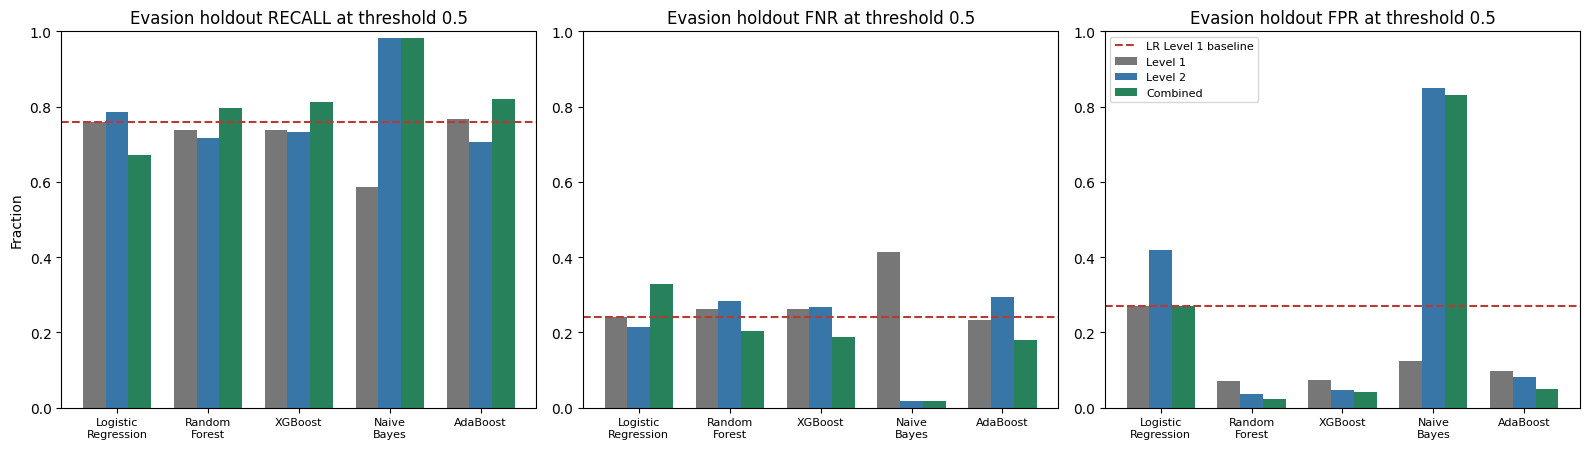

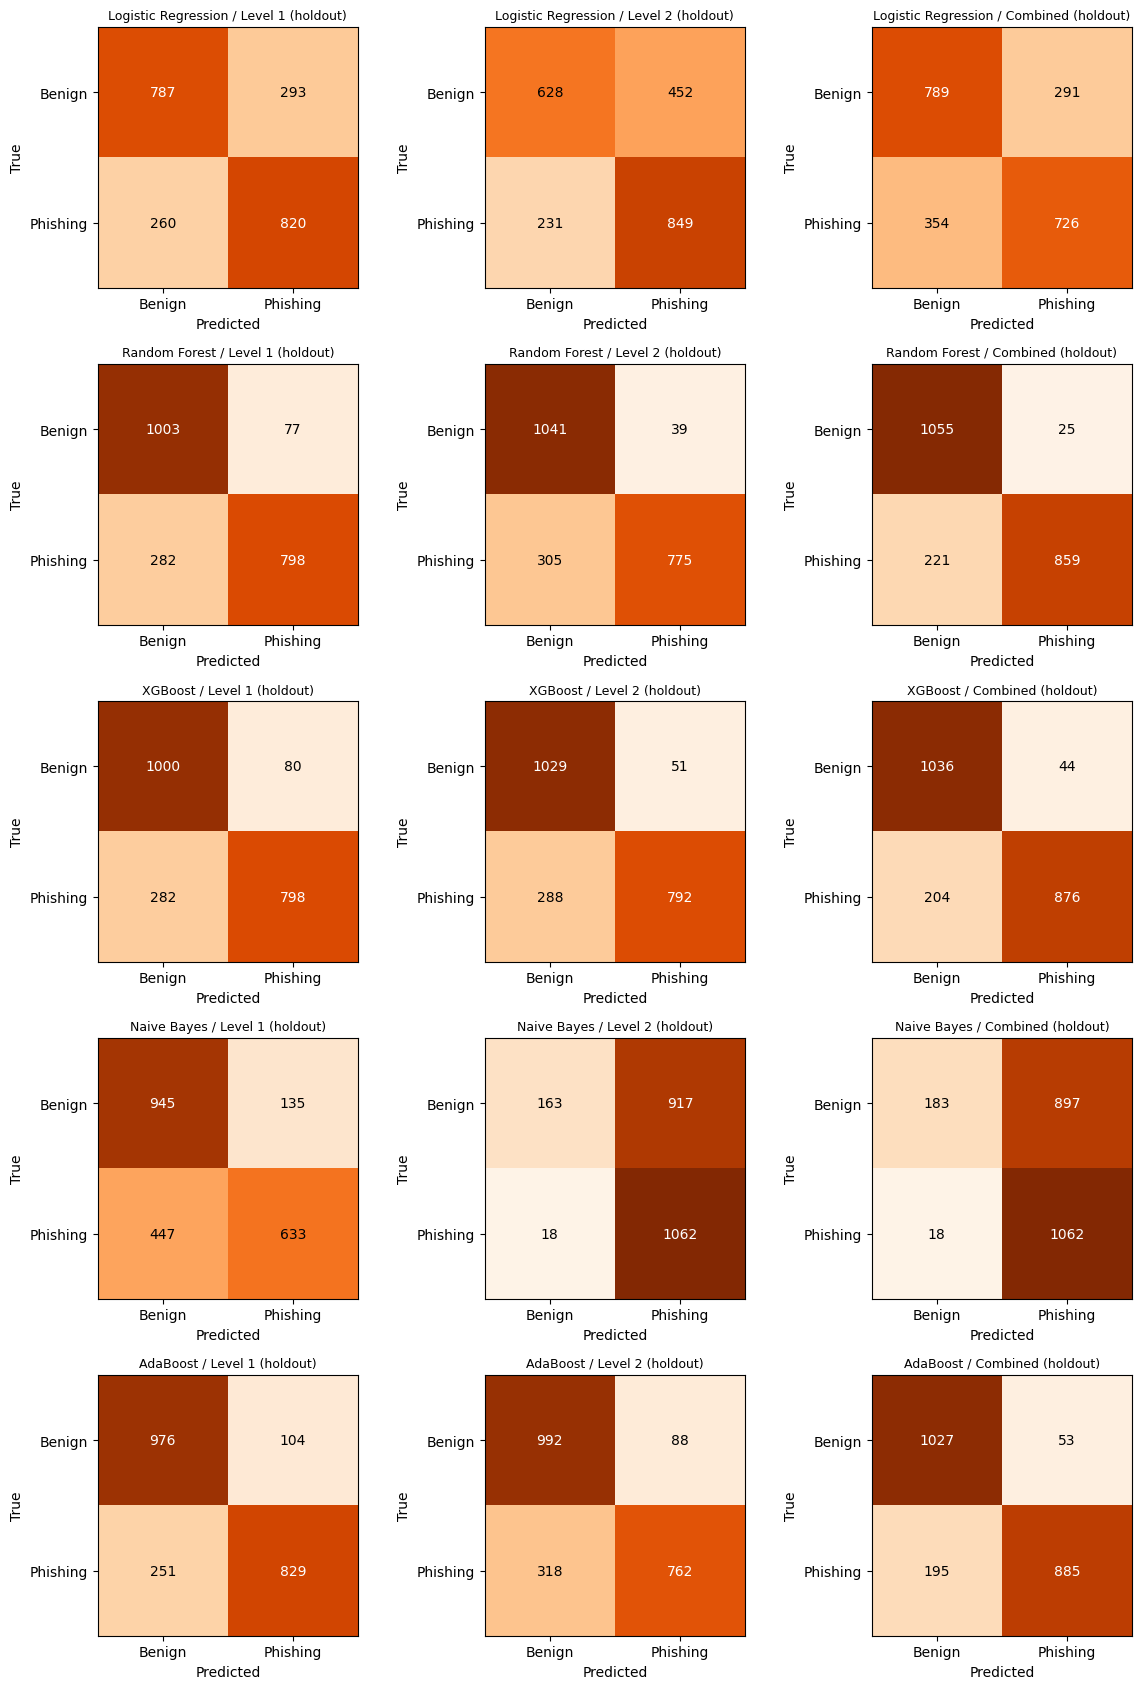

In [ ]:
# ---- metrics, bootstrap intervals and deltas for all 15 combinations on the evasion holdout
hneg=np.flatnonzero(yh==0); hpos=np.flatnonzero(yh==1)
rng_h=np.random.default_rng(SEED+7)
bpos=rng_h.choice(hpos,(N_BOOT,len(hpos)),replace=True); bneg=rng_h.choice(hneg,(N_BOOT,len(hneg)),replace=True)
R=results.set_index('combination'); hrows=[]
for source in record['models']:
    c,f=source['classifier'],source['feature_set']; k=key(c,f)
    m=metrics(yh,hprob[k]); rec_b=hpred[k][bpos].mean(axis=1); fpr_b=hpred[k][bneg].mean(axis=1)
    hrows.append(dict(combination=k,classifier=c,feature_set=f,threshold=.5,**m,
        recall_ci_low=np.quantile(rec_b,.025),recall_ci_high=np.quantile(rec_b,.975),
        fpr_ci_low=np.quantile(fpr_b,.025),fpr_ci_high=np.quantile(fpr_b,.975),
        test_recall=R.loc[k,'recall'],test_fpr=R.loc[k,'fpr']))
hres=pd.DataFrame(hrows); hb=hres.set_index('combination').loc[BASE]
for metric in ['recall','fnr','fpr','f1']: hres[f'delta_{metric}_vs_baseline_pp']=100*(hres[metric]-hb[metric])
hres['recall_change_from_test_pp']=100*(hres.recall-hres.test_recall)
save_table(hres,'evasion_holdout_comparison_15')

# ---- within-classifier feature comparison on the holdout (exact McNemar on phishing rows for recall, benign rows for FPR)
hpaired=[]
for c in CLASSIFIERS:
    for f in ['Level 2','Combined']:
        k,ref=key(c,f),key(c,'Level 1'); a,b=hpred[k],hpred[ref]
        caught=int(((a[hpos]==1)&(b[hpos]==0)).sum()); missed=int(((a[hpos]==0)&(b[hpos]==1)).sum())
        fp_removed=int(((a[hneg]==0)&(b[hneg]==1)).sum()); fp_added=int(((a[hneg]==1)&(b[hneg]==0)).sum())
        A,B=hres.set_index('combination').loc[k],hres.set_index('combination').loc[ref]
        hpaired.append(dict(classifier=c,feature_set=f,combination=k,reference=ref,
            delta_recall_pp=100*(A.recall-B.recall),delta_fnr_pp=100*(A.fnr-B.fnr),delta_fpr_pp=100*(A.fpr-B.fpr),
            phishing_newly_caught=caught,phishing_newly_missed=missed,
            recall_mcnemar_p=binomtest(caught,caught+missed,.5).pvalue if caught+missed else 1.,
            benign_false_alarms_removed=fp_removed,benign_false_alarms_added=fp_added,
            fpr_mcnemar_p=binomtest(fp_removed,fp_removed+fp_added,.5).pvalue if fp_removed+fp_added else 1.))
hpaired=pd.DataFrame(hpaired)
hpaired['recall_mcnemar_p_holm']=holm(hpaired.recall_mcnemar_p); hpaired['fpr_mcnemar_p_holm']=holm(hpaired.fpr_mcnemar_p)
save_table(hpaired,'evasion_holdout_paired_comparisons')

# ---- false positive rate per benign group (test and holdout) and recall by domain familiarity (holdout)
grp_rows=[]
for set_name,idx,preds in [('test',test_idx,predictions),('evasion_holdout',holdout_idx,hpred)]:
    g=raw.benign_group.iloc[idx].to_numpy(); yy=y[idx]
    for k,pr in preds.items():
        for grp in BENIGN_GROUPS:
            msk=(yy==0)&(g==grp)
            grp_rows.append(dict(evaluation_set=set_name,combination=k,benign_group=grp,n_benign=int(msk.sum()),
                                 false_positives=int(pr[msk].sum()),fpr=float(pr[msk].mean()) if msk.any() else np.nan))
benign_group_fpr=pd.DataFrame(grp_rows); save_table(benign_group_fpr,'benign_group_fpr')
dom_rows=[]
for k,pr in hpred.items():
    for label_,msk in [('domain seen in training',seen_h&(yh==1)),('domain unseen in training',~seen_h&(yh==1))]:
        dom_rows.append(dict(combination=k,slice=label_,n_phishing=int(msk.sum()),recall=float(pr[msk].mean())))
holdout_domain=pd.DataFrame(dom_rows); save_table(holdout_domain,'evasion_holdout_domain_overlap')

# ---- export holdout predictions (row positions, no URLs)
hp_out=pd.DataFrame({'row_index':holdout_idx,'label':yh,'registered_domain_seen':seen_h,'benign_group':raw.benign_group.iloc[holdout_idx].to_numpy()})
for k in hprob: hp_out[k+'__probability']=hprob[k]; hp_out[k+'__prediction']=hpred[k]
save_table(hp_out,'evasion_holdout_predictions')

print(f'Evasion-heavy holdout: {len(hpos):,} phishing URLs first seen {hp_dates.min():%Y-%m-%d} to {hp_dates.max():%Y-%m-%d} '
      f'+ {len(hneg):,} benign URLs | threshold 0.5')
display(hres[['classifier','feature_set','recall','recall_ci_low','recall_ci_high','fnr','fpr','f1','fn','fp',
              'delta_recall_vs_baseline_pp','recall_change_from_test_pp']].round(4))
print('Within-classifier feature comparison on the holdout (Level 2 / Combined vs. the same classifier on Level 1):')
display(hpaired[['classifier','feature_set','delta_recall_pp','delta_fnr_pp','delta_fpr_pp','phishing_newly_caught',
                 'phishing_newly_missed','recall_mcnemar_p_holm','fpr_mcnemar_p_holm']].round(4))
print('False positive rate per benign group on the holdout (rows = combination):')
display(benign_group_fpr[benign_group_fpr.evaluation_set=='evasion_holdout'].pivot(index='combination',columns='benign_group',values='fpr').loc[results.combination].round(4))
print('Holdout phishing recall by whether the registered domain also occurs in training:')
display(holdout_domain.pivot(index='combination',columns='slice',values='recall').loc[results.combination].round(4))

# ---- figures: recall/FNR/FPR by feature set, and the 15 holdout confusion matrices
colors_h=['#777777','#3976A8','#27825B']
fig,axs=plt.subplots(1,3,figsize=(16,4.6))
for ax,metric in zip(axs,['recall','fnr','fpr']):
    for j,f in enumerate(FS):
        v=hres[hres.feature_set==f].set_index('classifier').loc[CLASSIFIERS]
        ax.bar(np.arange(5)+(j-1)*.25,v[metric],.25,label=f,color=colors_h[j])
    ax.axhline(hb[metric],ls='--',c='#B53C34',label='LR Level 1 baseline')
    ax.set_xticks(range(5),[c.replace(' ',chr(10)) for c in CLASSIFIERS],fontsize=8)
    ax.set_title('Evasion holdout '+metric.upper()+' at threshold 0.5');ax.set_ylim(0,1)
axs[0].set_ylabel('Fraction');axs[-1].legend(fontsize=8)
figure('10_evasion_holdout_recall_fnr_fpr')
vmax=len(yh)//2
fig,axs=plt.subplots(5,3,figsize=(12,17))
for i,c in enumerate(CLASSIFIERS):
    for j,f in enumerate(FS):
        row=hres[(hres.classifier==c)&(hres.feature_set==f)].iloc[0];ax=axs[i,j]
        cm=np.array([[row.tn,row.fp],[row.fn,row.tp]],int)
        ax.imshow(cm,cmap='Oranges',vmin=0,vmax=vmax)
        for (a_,b_),v in np.ndenumerate(cm):ax.text(b_,a_,str(v),ha='center',va='center',color='white' if v>0.6*vmax else 'black')
        ax.set_xticks([0,1],['Benign','Phishing']);ax.set_yticks([0,1],['Benign','Phishing'])
        ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title(c+' / '+f+' (holdout)',fontsize=9)
figure('11_evasion_holdout_confusion_matrices_15')

## 5. Supplementary: heuristic evasion indicators and domain overlap (test set)
The primary evasion-heavy result is the temporal holdout in Section 4. The slices below are **supplementary heuristic diagnostics on the test set**, not ground truth for attack intent. Rules are fixed here before inspecting slice outcomes: encoded/redirect/nested query indicators; ≥3 subdomains; ≥4 path levels; or entropy/token variance above the **training-set 90th percentiles**. Test labels do not set thresholds. Because these indicators are computed from the same features the models use, the slices are partly circular and are reported only alongside the holdout result. Per-rule support is shown because rare subsets can give unstable rates. No subset membership is fed back into training or used to change model thresholds.

The domain-unseen slice contains only test rows whose registered domains are absent from training. It diagnoses the random split's overlap; it does not replace retraining with a domain-disjoint split and domain-disjoint CV. Counts below 30 receive an explicit small-support flag.

In [ ]:
rtest=raw.iloc[test_idx].reset_index(drop=True)
rtrain=raw.iloc[train_idx]
cutoffs={f:float(rtrain[f].quantile(.90)) for f in ['domain_entropy','token_variance']}
rules={
 'encoded_query':rtest.query_encoding_ratio.to_numpy()>0,
 'redirect_key':rtest.redirect_key_flag.to_numpy()==1,
 'nested_url':rtest.nested_url_flag.to_numpy()==1,
 'deep_subdomain':rtest.subdomain_count.to_numpy()>=3,
 'deep_path':rtest.path_depth.to_numpy()>=4,
 'high_domain_entropy':rtest.domain_entropy.to_numpy()>cutoffs['domain_entropy'],
 'high_token_variance':rtest.token_variance.to_numpy()>cutoffs['token_variance']}
proxy=np.logical_or.reduce(list(rules.values()))
slices={'all_test':np.ones(len(yt),bool),'evasion_indicator_proxy':proxy,
        'no_evasion_indicator_proxy':~proxy,'exact_url_not_in_training':~exact_url_seen,'domain_seen_in_training':seen,'domain_unseen_in_training':~seen,**rules}
subset_rows=[]
for name,mask in slices.items():
    for k,p in probabilities.items():
        count=int(mask.sum()); npos=int((yt[mask]==1).sum());nneg=count-npos
        m=metrics(yt[mask],p[mask]) if count else {}
        subset_rows.append(dict(slice=name,combination=k,n_benign=nneg,n_phishing=npos,
                               small_support=(min(npos,nneg)<30),**m))
subsets=pd.DataFrame(subset_rows);save_table(subsets,'subset_evaluation')
support=pd.DataFrame([{'slice':name,'n':int(mask.sum()),'benign':int((yt[mask]==0).sum()),'phishing':int((yt[mask]==1).sum())} for name,mask in slices.items()])
save_table(support,'subset_support');display(support)
display(subsets[subsets.slice=='evasion_indicator_proxy'][['combination','n_benign','n_phishing','recall','fnr','fpr','small_support']].round(4))
# Export sample-level predictions without active URL hyperlinks.
pr=pd.DataFrame({'row_index':test_idx,'label':yt,'registered_domain_seen':seen,'exact_url_seen_in_training':exact_url_seen,'evasion_indicator_proxy':proxy})
for k,p in probabilities.items():pr[k+'__probability']=p;pr[k+'__prediction']=predictions[k]
save_table(pr,'test_predictions')
# Defang URLs in error examples to prevent accidental clicks.
def defang(s):return str(s).replace('https://','hxxps://').replace('http://','hxxp://').replace('.', '[.]')
errors=[]
for k,pred in predictions.items():
    for error,label,predlabel in [('FP',0,1),('FN',1,0)]:
        ix=np.flatnonzero((yt==label)&(pred==predlabel))
        # Fixed sample order: no cherry-picking the most striking examples.
        for j in ix[:8]:
            errors.append(dict(combination=k,error_type=error,row_index=int(test_idx[j]),url_defanged=defang(rtest.iloc[j].url),
                probability=float(probabilities[k][j]),evasion_indicator_proxy=bool(proxy[j]),
                **{f:float(rtest.iloc[j][f]) for f in L1+L2}))
save_table(pd.DataFrame(errors),'error_examples_defanged')

,slice,n,benign,phishing
0,all_test,1568,784,784
1,evasion_indicator_proxy,450,164,286
2,no_evasion_indicator_proxy,1118,620,498
3,exact_url_not_in_training,1568,784,784
4,domain_seen_in_training,885,210,675
5,domain_unseen_in_training,683,574,109
6,encoded_query,110,97,13
7,redirect_key,11,7,4
8,nested_url,36,23,13
9,deep_subdomain,33,1,32


,combination,n_benign,n_phishing,recall,fnr,fpr,small_support
15,logistic_regression__level_1,164,286,0.7308,0.2692,0.2195,False
16,logistic_regression__level_2,164,286,0.8636,0.1364,0.2988,False
17,logistic_regression__combined,164,286,0.8741,0.1259,0.1951,False
18,random_forest__level_1,164,286,0.9126,0.0874,0.0671,False
19,random_forest__level_2,164,286,0.9545,0.0455,0.0427,False
20,random_forest__combined,164,286,0.9476,0.0524,0.0427,False
21,xgboost__level_1,164,286,0.9266,0.0734,0.0793,False
22,xgboost__level_2,164,286,0.9510,0.0490,0.0671,False
23,xgboost__combined,164,286,0.9720,0.0280,0.0244,False
24,naive_bayes__level_1,164,286,0.6643,0.3357,0.1707,False


,combination,error_type,row_index,url_defanged,probability,evasion_indicator_proxy,url_length,domain_length,path_length,subdomain_count,path_depth,query_params_count,digit_ratio,special_char_ratio,token_variance,domain_entropy,redirect_key_flag,nested_url_flag,query_encoding_ratio
0,logistic_regression__level_1,FP,31,www[.]diariovasco[.]com/category/2026/package-...,0.548945,False,49.0,19.0,30.0,1.0,3.0,0.0,0.081633,0.122449,8.809524,3.326360,0.0,0.0,0.0
1,logistic_regression__level_1,FP,59,www[.]aasaam-ns[.]net,0.517140,False,17.0,17.0,0.0,1.0,0.0,0.0,0.000000,0.176471,3.000000,2.984234,0.0,0.0,0.0
2,logistic_regression__level_1,FP,73,happy-bush-0c5d10603[.]1[.]azurestaticapps[.]n...,0.797145,True,130.0,42.0,88.0,2.0,2.0,0.0,0.207692,0.138462,14.888889,4.272804,0.0,0.0,0.0
3,logistic_regression__level_1,FP,237,www[.]windows-int[.]net,0.541226,False,19.0,19.0,0.0,1.0,0.0,0.0,0.000000,0.157895,4.000000,3.070847,0.0,0.0,0.0
4,logistic_regression__level_1,FP,359,www[.]optimizely[.]com/docs/youth/apple-people...,0.537980,False,52.0,18.0,34.0,1.0,3.0,0.0,0.000000,0.153846,6.000000,3.461320,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,adaboost__combined,FN,412,au[.]natostrap[.]com/mobile/login,0.460621,False,29.0,16.0,13.0,1.0,2.0,0.0,0.000000,0.137931,7.500000,3.327820,0.0,0.0,0.0
236,adaboost__combined,FN,613,linkin[.]bio/kunder,0.475780,False,17.0,10.0,7.0,0.0,1.0,0.0,0.000000,0.117647,3.000000,2.646439,0.0,0.0,0.0
237,adaboost__combined,FN,761,mj-api[.]kun-ai[.]com/blog/discord-bots-and-ap...,0.486724,False,66.0,17.0,49.0,1.0,2.0,0.0,0.000000,0.166667,9.719697,3.499228,0.0,0.0,0.0
238,adaboost__combined,FN,1230,sites[.]google[.]com/view/gmx-net-mainkonto/home,0.492639,False,44.0,16.0,28.0,1.0,3.0,0.0,0.000000,0.159091,4.267857,3.202820,0.0,0.0,0.0


## 6. Classification, uncertainty, and error plots (test set)
All scores shown below use the primary 0.5 threshold. Confusion matrices have true classes on rows and predicted classes on columns. Test-to-CV comparisons are descriptive because the CV score was used for model selection. A low train/test gap alone does not prove absence of overfitting.

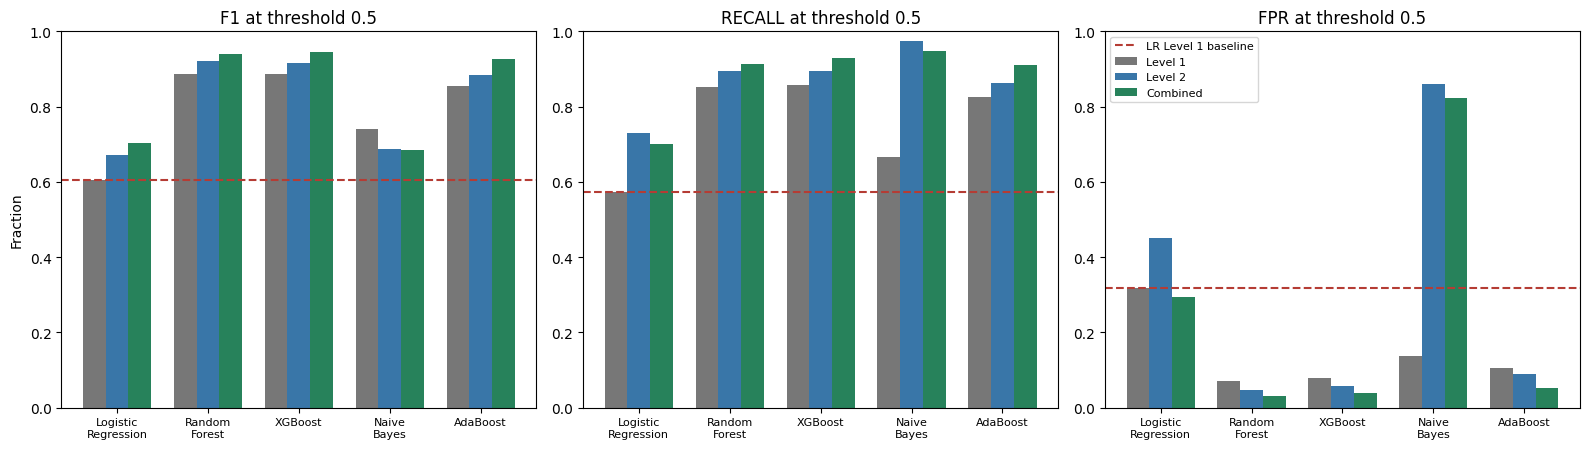

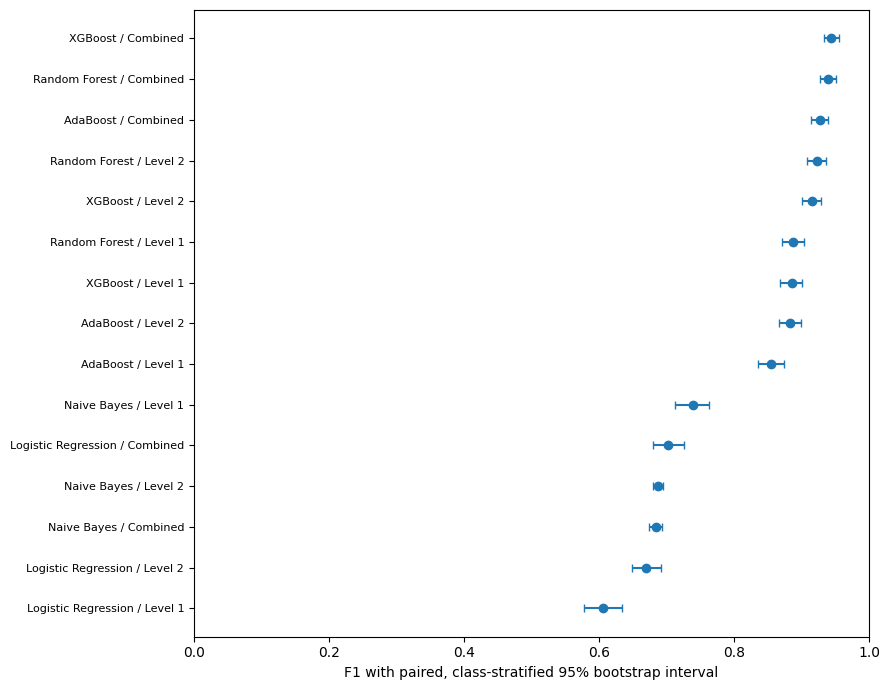

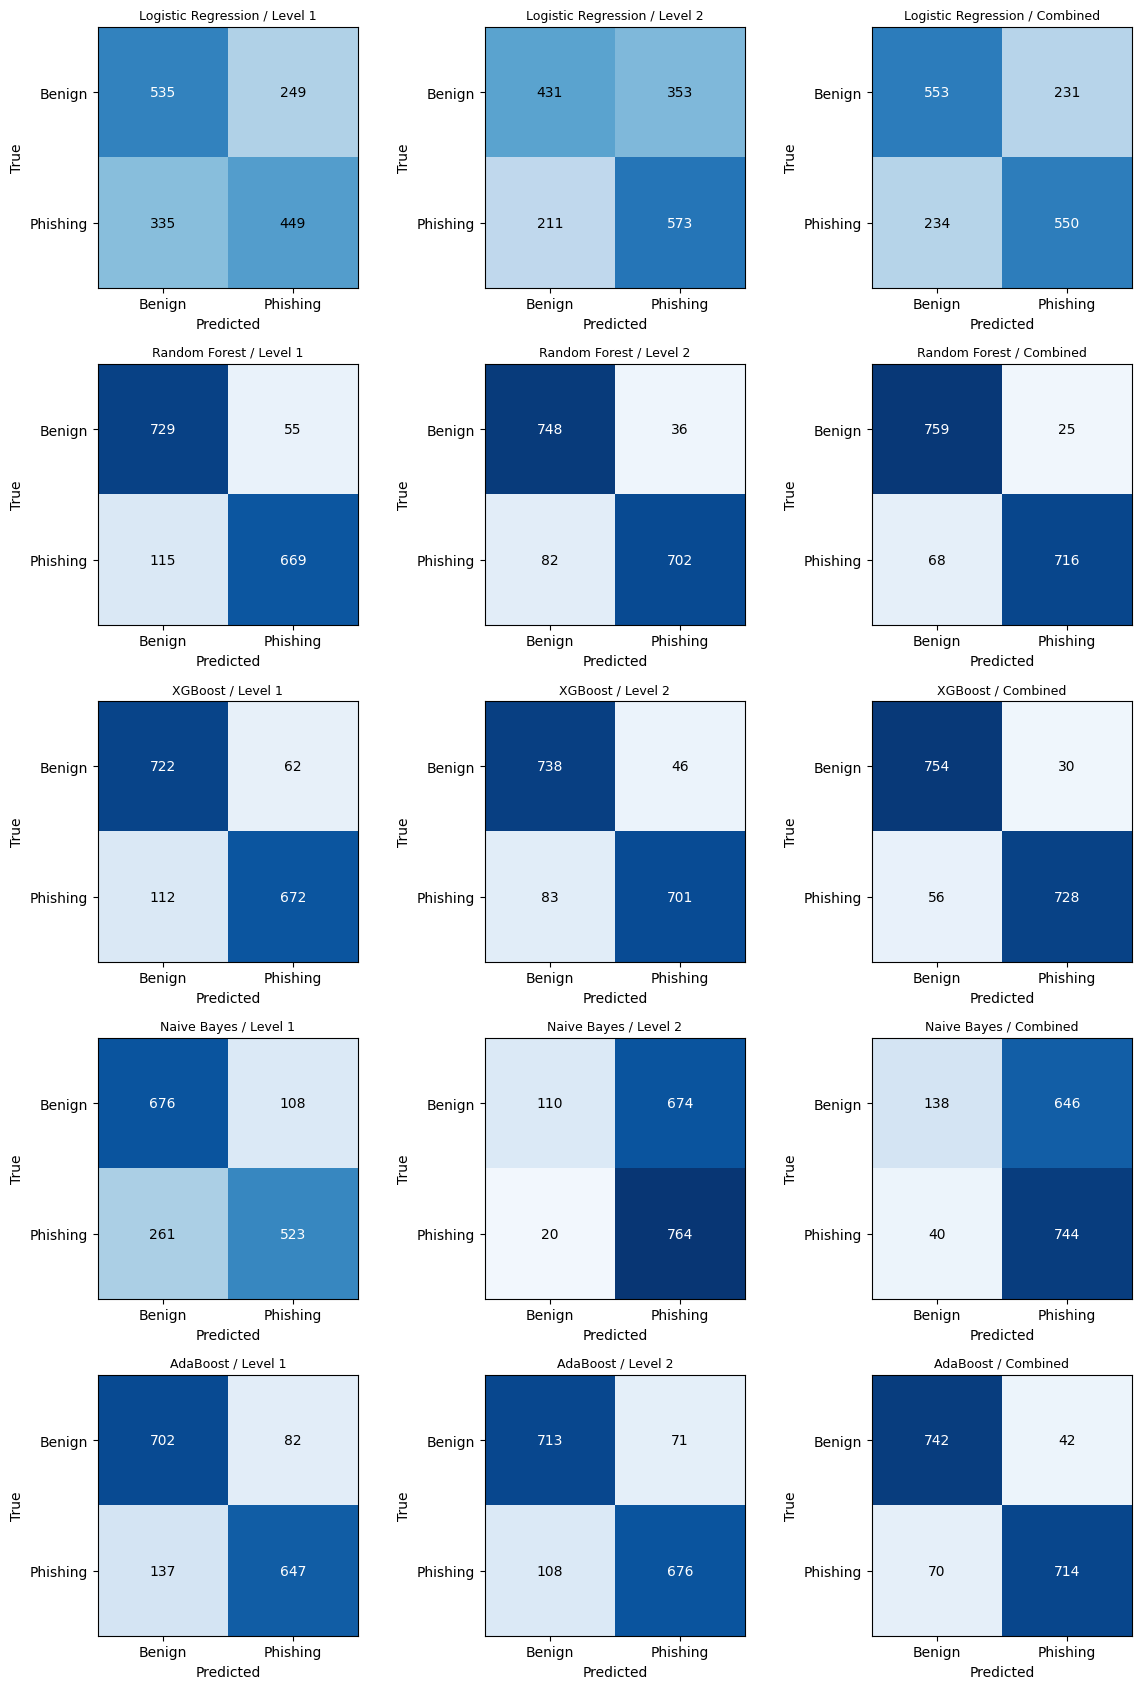

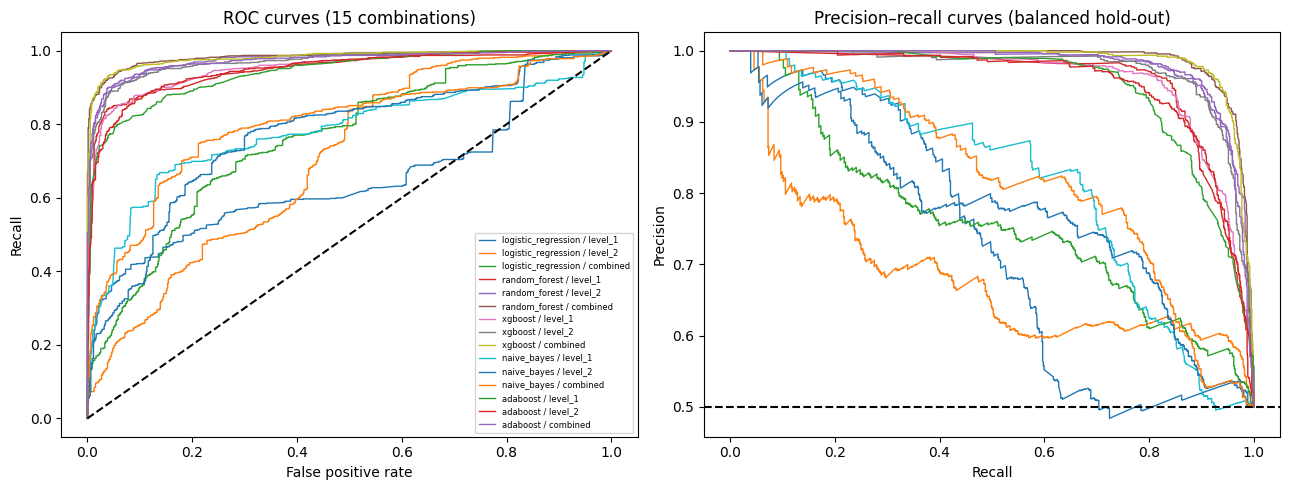

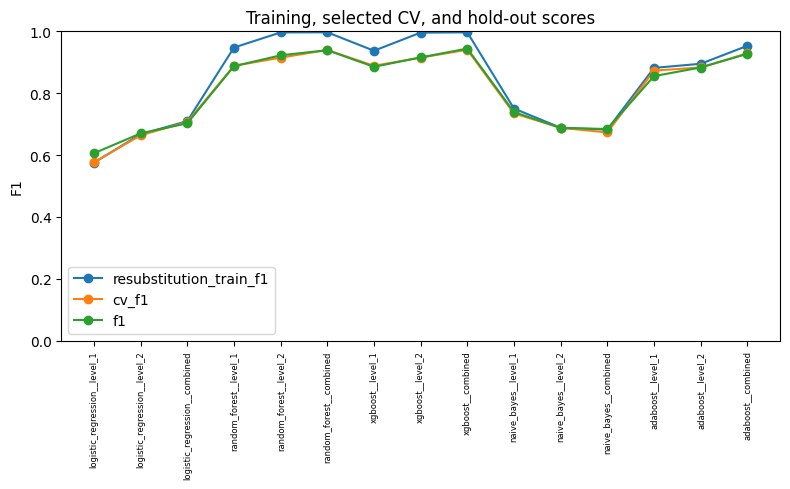

In [ ]:
colors=['#777777','#3976A8','#27825B']
fig,axs=plt.subplots(1,3,figsize=(16,4.6))
for ax,metric in zip(axs,['f1','recall','fpr']):
    for j,f in enumerate(FS):
        v=results[results.feature_set==f].set_index('classifier').loc[CLASSIFIERS]
        ax.bar(np.arange(5)+(j-1)*.25,v[metric],.25,label=f,color=colors[j])
    ax.axhline(base[metric],ls='--',c='#B53C34',label='LR Level 1 baseline')
    ax.set_xticks(range(5),[c.replace(' ',chr(10)) for c in CLASSIFIERS],fontsize=8)
    ax.set_title(metric.upper()+' at threshold 0.5');ax.set_ylim(0,1)
axs[0].set_ylabel('Fraction');axs[-1].legend(fontsize=8)
figure('01_feature_comparison')

fig,ax=plt.subplots(figsize=(9,7));v=results.sort_values('f1').reset_index(drop=True)
ax.errorbar(v.f1,range(15),xerr=np.vstack([v.f1-v.f1_ci_low,v.f1_ci_high-v.f1]),fmt='o',capsize=3)
ax.set_yticks(range(15),v.classifier+' / '+v.feature_set,fontsize=8);ax.set_xlim(0,1)
ax.set_xlabel('F1 with paired, class-stratified 95% bootstrap interval');figure('02_f1_intervals')

fig,axs=plt.subplots(5,3,figsize=(12,17))
for i,c in enumerate(CLASSIFIERS):
 for j,f in enumerate(FS):
    row=results[(results.classifier==c)&(results.feature_set==f)].iloc[0];ax=axs[i,j]
    cm=np.array([[row.tn,row.fp],[row.fn,row.tp]],int)
    ax.imshow(cm,cmap='Blues',vmin=0,vmax=len(yt)//2)
    for (a,b),v in np.ndenumerate(cm):ax.text(b,a,str(v),ha='center',va='center',color='white' if v>0.6*len(yt)//2 else 'black')
    ax.set_xticks([0,1],['Benign','Phishing']);ax.set_yticks([0,1],['Benign','Phishing'])
    ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title(c+' / '+f,fontsize=9)
figure('03_confusion_matrices_15')

fig,axs=plt.subplots(1,2,figsize=(13,5))
for k,p in probabilities.items():
    fpr,tpr,_=roc_curve(yt,p);prec,rec,_=precision_recall_curve(yt,p)
    axs[0].plot(fpr,tpr,label=k.replace('__',' / '),lw=1)
    axs[1].plot(rec,prec,lw=1)
axs[0].plot([0,1],[0,1],'k--');axs[1].axhline(yt.mean(),c='k',ls='--')
axs[0].set(xlabel='False positive rate',ylabel='Recall',title='ROC curves (15 combinations)')
axs[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curves (balanced hold-out)')
axs[0].legend(fontsize=6,loc='lower right');figure('04_roc_pr')

fig,ax=plt.subplots(figsize=(8,5))
for f in ['resubstitution_train_f1','cv_f1','f1']:
    ax.plot(np.arange(15),results[f],marker='o',label=f)
ax.set_xticks(range(15),results.combination,rotation=90,fontsize=6);ax.set_ylim(0,1)
ax.set_ylabel('F1');ax.legend();ax.set_title('Training, selected CV, and hold-out scores');figure('05_generalization_diagnostic')

## 7. Interpretability and probability diagnostics
For every combined model, permutation importance measures the change in hold-out **F1 at the fixed 0.5 threshold** after one feature is shuffled, with three seeded repetitions. This uses the complete test set. Correlated length/depth features can share signal, so importance is model-dependent and does not demonstrate causality. These diagnostics must not be used to reselect features on the same test set.

Reliability curves and Brier scores check probability behavior. No calibration is fitted here; Naïve Bayes and boosting probabilities may not be calibrated. A high score cannot be interpreted as a validated probability of obfuscation.

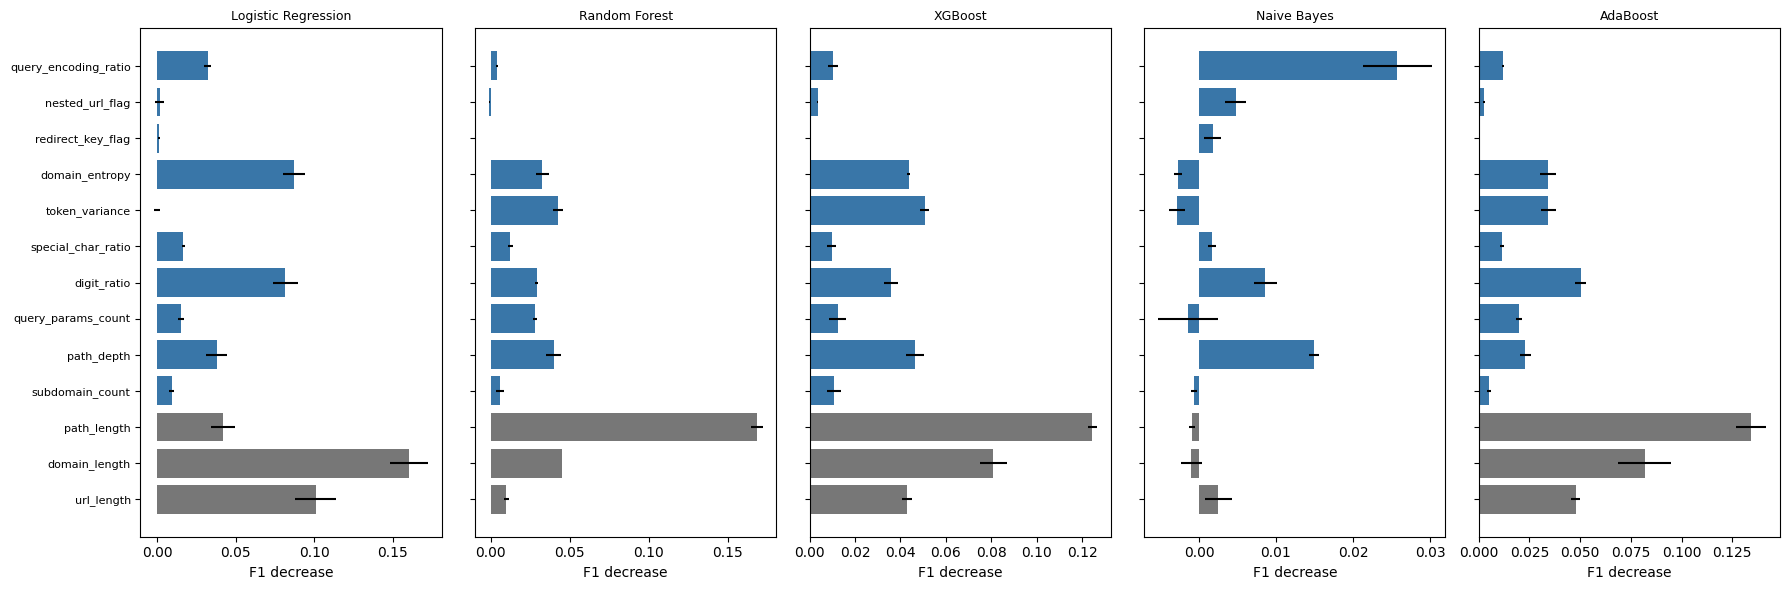

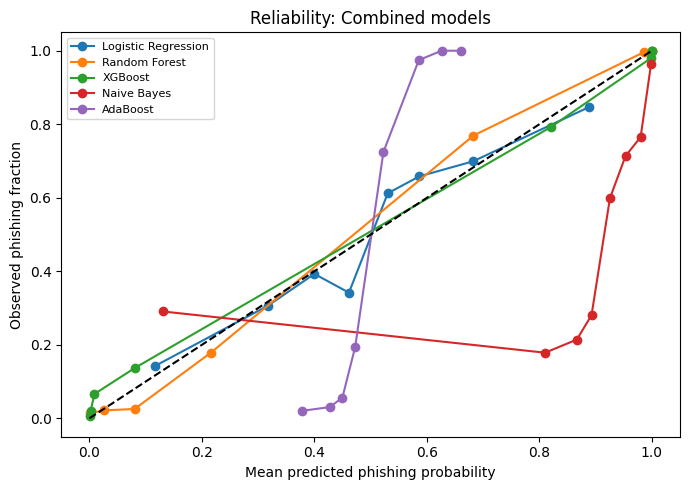

In [ ]:
importance=[];perm_rng=np.random.default_rng(SEED)
for c in CLASSIFIERS:
    k=key(c,'Combined'); model=bundles[k]['model']; X=raw.iloc[test_idx][L1+L2].to_numpy(float)   # RAW features
    score=f1_score(yt,predictions[k])
    for j,f in enumerate(L1+L2):
        drops=[]
        for rep in range(3):
            xp=X.copy();xp[:,j]=xp[perm_rng.permutation(len(xp)),j]
            pp=model.predict_proba(xp)[:,1]
            drops.append(score-f1_score(yt,pp>=.5))
        importance.append(dict(classifier=c,feature=f,level='Level 1' if f in L1 else 'Level 2',
                               f1_drop_mean=float(np.mean(drops)),f1_drop_std=float(np.std(drops)),repeats=3,n=len(yt)))
importance=pd.DataFrame(importance);save_table(importance,'permutation_importance_combined')
fig,axs=plt.subplots(1,5,figsize=(18,6),sharey=True)
for ax,c in zip(axs,CLASSIFIERS):
    v=importance[importance.classifier==c].set_index('feature').loc[L1+L2]
    ax.barh(range(13),v.f1_drop_mean,xerr=v.f1_drop_std,color=[colors[0] if f in L1 else colors[1] for f in L1+L2])
    ax.set_yticks(range(13),L1+L2,fontsize=8);ax.set_title(c,fontsize=9);ax.set_xlabel('F1 decrease')
figure('06_permutation_importance')
fig,ax=plt.subplots(figsize=(7,5))
for c in CLASSIFIERS:
    p=probabilities[key(c,'Combined')]
    obs,mean=calibration_curve(yt,p,n_bins=8,strategy='quantile')
    ax.plot(mean,obs,'o-',label=c)
ax.plot([0,1],[0,1],'k--');ax.set(xlabel='Mean predicted phishing probability',ylabel='Observed phishing fraction',title='Reliability: Combined models')
ax.legend(fontsize=8);figure('07_probability_reliability')

## 8. Resource comparison and extraction evidence
Training resource figures belong to the original recorded environment. The original resource sampler polls the main process RSS; it may miss short peaks. Current inference is serial, warmed up, one timed call per URL (2,000 timed calls/model), with mean, median, and p95. Model sizes are disk sizes, not resident memory.

The extraction notebook displays rounded per-phase wall times in its saved output. The code below reads those **recorded outputs**, rather than pretending that CSV loading is feature extraction. Shared parsing cost is added to each feature configuration. These are historical, rounded measurements; the combined total may differ slightly from the sum due to rounding. They were not measured in this runtime and are not end-to-end deployment latency. If the extraction output changes format or is missing, the measure remains unavailable and is explicitly reported.

,combination,classifier,feature_set,training_time_s_historical,training_peak_rss_mb_historical,training_peak_rss_increase_mb_historical,inference_ms_per_url_historical,inference_mean_ms_current,inference_p50_ms_current,inference_p95_ms_current,timed_calls,model_size_mb,extraction_10000_urls_s_historical_rounded,extraction_source
0,logistic_regression__level_1,Logistic Regression,Level 1,6.4340,275.1719,1.9805,1.3690,1.7382,1.2926,4.8914,1568,0.0026,0.232,Module 3–4 saved rounded profile table; shared...
1,logistic_regression__level_2,Logistic Regression,Level 2,10.2714,278.2461,2.2656,0.8194,3.9793,2.3242,10.3793,1568,0.0035,1.000,Module 3–4 saved rounded profile table; shared...
2,logistic_regression__combined,Logistic Regression,Combined,8.2735,280.7773,1.8633,0.8511,5.5650,4.2096,14.3883,1568,0.0037,1.009,Module 3–4 saved rounded profile table; shared...
3,random_forest__level_1,Random Forest,Level 1,61.2389,288.3867,7.5859,6.4806,23.9829,15.3640,59.0888,1568,8.0248,0.232,Module 3–4 saved rounded profile table; shared...
4,random_forest__level_2,Random Forest,Level 2,100.3844,302.2109,13.7148,7.0727,10.0671,8.1801,15.1589,1568,9.4644,1.000,Module 3–4 saved rounded profile table; shared...
5,random_forest__combined,Random Forest,Combined,99.1057,308.8281,14.2500,17.2390,25.3629,20.9733,38.2414,1568,23.0600,1.009,Module 3–4 saved rounded profile table; shared...
6,xgboost__level_1,XGBoost,Level 1,9.6002,337.9297,4.9219,0.9284,1.7918,1.3373,4.5869,1568,0.5277,0.232,Module 3–4 saved rounded profile table; shared...
7,xgboost__level_2,XGBoost,Level 2,15.4239,337.9414,0.0078,1.1945,2.5318,1.7246,7.3658,1568,0.8546,1.000,Module 3–4 saved rounded profile table; shared...
8,xgboost__combined,XGBoost,Combined,18.8271,337.9453,0.0039,1.1982,2.6886,2.4045,3.6320,1568,0.7650,1.009,Module 3–4 saved rounded profile table; shared...
9,naive_bayes__level_1,Naive Bayes,Level 1,0.3440,337.9531,0.0039,0.9666,1.2280,1.1402,1.6359,1568,0.0025,0.232,Module 3–4 saved rounded profile table; shared...


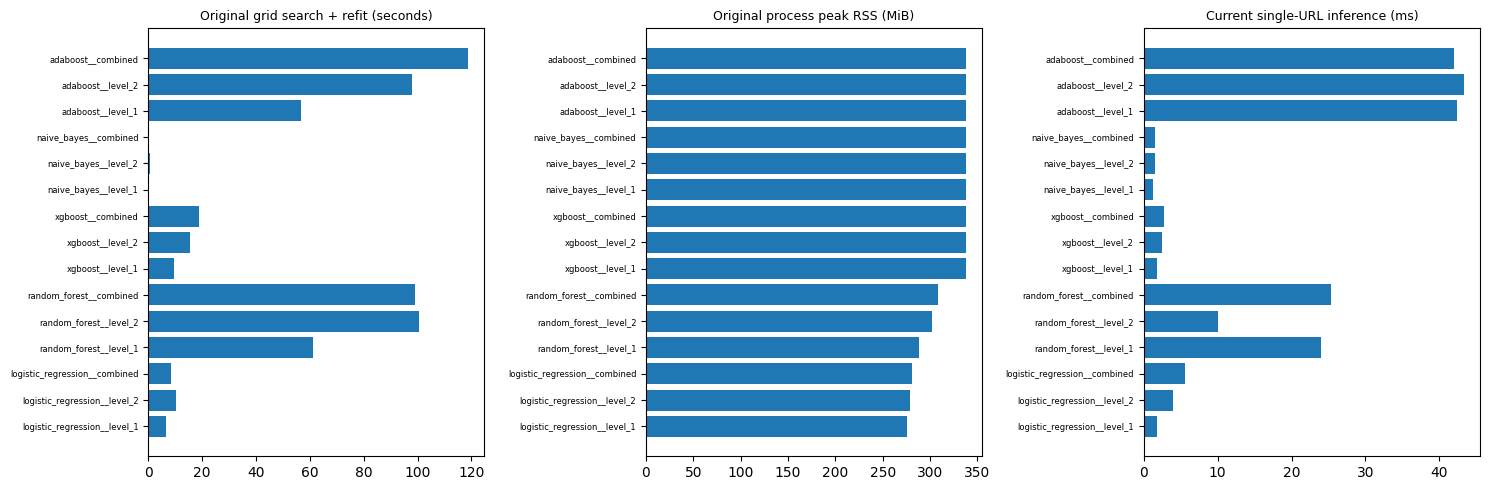

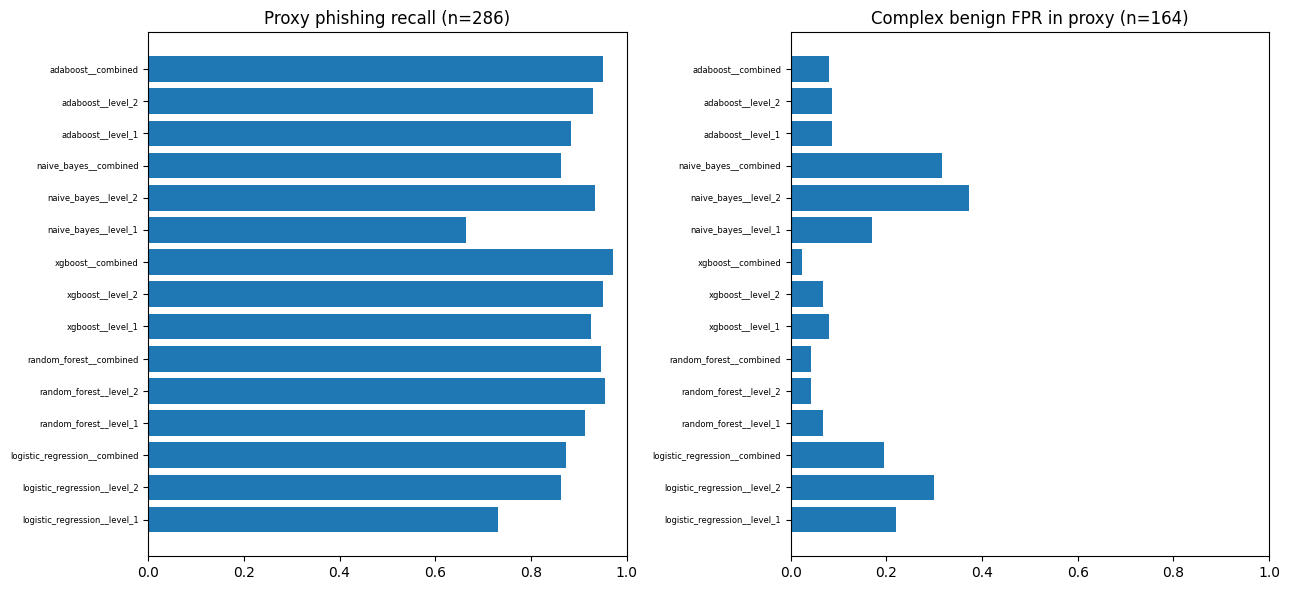

In [ ]:
exnb=json.loads((ROOT/'Modules/3_4_feature_extraction_pipeline.ipynb').read_text())
phase_times={}
for cell in exnb['cells']:
    if 'profile_table.round' not in ''.join(cell.get('source',[])): continue
    for out in cell.get('outputs',[]):
        text=''.join(out.get('data',{}).get('text/plain',[]))
        for line in text.splitlines():
            match=re.match(r'^\s*([0-5])\s+(.+?)\s+(\d+)\s+\d{2}:\d{2}:\d{2}\s+\d{2}:\d{2}:\d{2}\s+([\d.]+)',line)
            if match:phase_times[int(match[1])]=float(match[4])
extraction={'Level 1':phase_times.get(0,np.nan)+phase_times.get(1,np.nan),
            'Level 2':phase_times.get(0,np.nan)+phase_times.get(4,np.nan),
            'Combined':phase_times.get(5,np.nan)}
resources=results[['combination','classifier','feature_set','training_time_s_historical',
    'training_peak_rss_mb_historical','training_peak_rss_increase_mb_historical',
    'inference_ms_per_url_historical','inference_mean_ms_current','inference_p50_ms_current','inference_p95_ms_current','timed_calls']].copy()
resources=resources.merge(pd.DataFrame(model_audit)[['combination','model_size_mb']],on='combination',validate='one_to_one')
resources['extraction_10000_urls_s_historical_rounded']=resources.feature_set.map(extraction)
resources['extraction_source']='Module 3–4 saved rounded profile table; shared parsing included'
save_table(resources,'resource_comparison');display(resources.round(4))
fig,axs=plt.subplots(1,3,figsize=(15,5))
for ax,col,title in zip(axs,['training_time_s_historical','training_peak_rss_mb_historical','inference_mean_ms_current'],
                       ['Original grid search + refit (seconds)','Original process peak RSS (MiB)','Current single-URL inference (ms)']):
    ax.barh(range(15),resources[col]);ax.set_yticks(range(15),resources.combination,fontsize=6);ax.set_title(title,fontsize=9)
figure('08_resource_profile')
# Subset plots include support and explicitly use the proxy label.
fig,axs=plt.subplots(1,2,figsize=(13,6))
v=subsets[subsets.slice=='evasion_indicator_proxy'].set_index('combination').loc[results.combination]
axs[0].barh(range(15),v.recall);axs[1].barh(range(15),v.fpr)
for ax in axs:ax.set_yticks(range(15),results.combination,fontsize=6);ax.set_xlim(0,1)
axs[0].set_title('Proxy phishing recall (n='+str(int(v.n_phishing.iloc[0]))+')')
axs[1].set_title('Complex benign FPR in proxy (n='+str(int(v.n_benign.iloc[0]))+')')
figure('09_proxy_subset')

## 9. Evidence package, limitations, and completion checks
The primary table has exactly **15 rows** and one baseline reference. The baseline is one of the 15 combinations; the separately saved Module 6 artifact is a consistency check, not a sixteenth candidate. All metrics are recomputed from loaded models, not copied from saved scores.

**What the evaluation design now supports:** scaling is fitted on the `train` rows only (inside each pipeline and in `Final_Dataset.csv`); URLs are de-duplicated after normalization; every phishing URL has a first-seen date cross-checked against PhishTank / PhishStats; and the newest phishing URLs (first seen on or after 2026-03-01) form an evasion-heavy holdout that was excluded from training, tuning and threshold selection. The fixed 0.5 threshold is the decision rule; tuned thresholds are reported only as an adjustment aid.

**Limitations that remain:** the test set was displayed in Modules 6 and 7, so test results are provisional; the holdout's benign URLs are not dated (top-site lists carry no collection dates), so its false positive rate is not a temporal result; part of the holdout's phishing URLs share a registered domain with training phishing URLs (see `data_quality.csv`), so the holdout is temporal but not domain-disjoint; the heuristic evasion indicators in Section 5 are computed from the model features and are supplementary only; no verified evasion-intent labels, no live browsing/gateway claim, and no comparison with a trained deep learning model. Some proposal passages request component-wise entropy/ratios while Table 4.1 specifies a single domain entropy and URL-wide ratios; this experiment evaluates the implemented Table 4.1 representation. Normalizing the whole URL to lowercase can alter case-sensitive paths and Base64 payloads.

Primary methods reference: [scikit-learn: data leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [ ]:
assert len(results)==15 and set(zip(results.classifier,results.feature_set))==expected
assert results[['accuracy','precision','recall','f1','fpr','fnr','roc_auc','average_precision']].notna().all().all()
assert (results[['tn','fp','fn','tp']].sum(axis=1)==len(yt)).all()
assert all(len(p)==len(yt) for p in probabilities.values()) and all(len(p)==len(yh) for p in hprob.values())
assert len(hres)==15 and len(hpaired)==10
assert len(paired)==24 and len(model_audit)==15
hash_paths=['Dataset/Dataset.csv','Dataset/Final_Dataset.csv','Dataset/Extracted_Features.csv','Dataset/Preprocessed_Dataset.csv',
            'Models/train_test_split_indices.csv','Metrics/models_manifest.csv','Metrics/all_models_metrics.json',
            'Models/baseline_logistic_regression.joblib']
metadata=dict(study='Obfuscation-Aware Feature Engineering for Evasion-Heavy Phishing URL Detection',
    source_commit_reviewed='dated dataset (split column: train / test / evasion_holdout)',
    status='PROVISIONAL: test set previously inspected; evasion holdout temporal on the phishing side only',
    threshold=.5,seed=SEED,n_boot=N_BOOT,n_test=len(yt),class_counts={'benign':int((yt==0).sum()),'phishing':int((yt==1).sum())},
    n_train=len(yr),n_holdout=len(yh),holdout_class_counts={'benign':int((yh==0).sum()),'phishing':int((yh==1).sum())},
    holdout_cutoff=str(HOLDOUT_CUTOFF.date()),holdout_phishing_dates=[f'{hp_dates.min():%Y-%m-%d}',f'{hp_dates.max():%Y-%m-%d}'],
    heuristic_subset_cutoffs=cutoffs,feature_sets=FS,training_environment=record['environment'],
    evaluation_environment=dict(python=platform.python_version(),sklearn=sklearn.__version__,xgboost=xgboost.__version__,
        pandas=pd.__version__,numpy=np.__version__,scipy=scipy.__version__,platform=platform.platform(),
        logical_cpus=psutil.cpu_count(),ram_gb=psutil.virtual_memory().total/2**30,native_threads=1),
    input_sha256={p:sha(ROOT/p) for p in hash_paths},
    caveats=['test scores previously displayed in Modules 6 and 7','evasion holdout benign URLs are not dated',
             'some evasion holdout phishing domains also occur in training','heuristic evasion indicators are supplementary and partly circular','RSS includes retained models and runtime',
             'row bootstrap assumes independent URLs; domains may be shared','test ranking is exploratory; do not retune from it'])
(OUT/'evaluation_metadata.json').write_text(json.dumps(metadata,indent=2))
np.savez_compressed(OUT/'prediction_arrays.npz',row_index=test_idx,y_true=yt,**probabilities)
np.savez_compressed(OUT/'prediction_arrays_evasion_holdout.npz',row_index=holdout_idx,y_true=yh,**hprob)
print('Milestone 8 implementation complete: 15-combination table, verified baseline, paired comparisons, evasion-heavy holdout,')
print('uncertainty, error/subset analysis, importance, probability diagnostics, and resource figures exported.')
print('Scientific readiness: PROVISIONAL — see Section 9 limitations before final thesis claims.')
print('Next: run 9_preliminary_findings_results_writeup.ipynb. Outputs:', OUT)

Milestone 8 implementation complete: 15-combination table, verified baseline, paired comparisons, evasion-heavy holdout,
uncertainty, error/subset analysis, importance, probability diagnostics, and resource figures exported.
Scientific readiness: PROVISIONAL — see Section 9 limitations before final thesis claims.
Next: run 9_preliminary_findings_results_writeup.ipynb. Outputs: /content/PhishEvade/Results/milestone8


## 10. Completed performance comparison: 15 combinations vs. baseline
One row per classifier / feature-set combination at the fixed **0.5** threshold. The first block is the **test set**; the **Δ columns are percentage-point differences from the baseline** (Logistic Regression on Level 1 features; for FPR, a negative Δ is an improvement). Bootstrap intervals are paired, class-stratified 95% percentile intervals. The **holdout block** repeats recall, false negative rate and FPR on the **evasion-heavy holdout** (newest phishing URLs, never used for training or tuning), with the recall change vs. the baseline. The tuned-threshold block shows F1 and FPR at each model's training-set Youden's J threshold, as an **adjustment aid only**; the 0.5 columns remain the result. Time and latency are model-only figures (training time from Module 7's recorded machine, inference measured in this runtime).

In [ ]:
sens = pd.DataFrame(sensitivity).set_index('combination')
H = hres.set_index('combination')
ci = lambda lo, hi: [f'{a:.3f}-{b:.3f}' for a, b in zip(lo, hi)]
final_table = pd.DataFrame({
    'Role': np.where(results.combination == BASE, 'BASELINE', ''),
    'Classifier': results.classifier, 'Feature set': results.feature_set,
    'Accuracy': results.accuracy, 'Precision': results.precision, 'Recall': results.recall, 'F1': results.f1, 'FPR': results.fpr,
    'F1 95% CI': ci(results.f1_ci_low, results.f1_ci_high), 'FPR 95% CI': ci(results.fpr_ci_low, results.fpr_ci_high),
    'dAccuracy (pp)': results.delta_accuracy_vs_baseline_pp, 'dRecall (pp)': results.delta_recall_vs_baseline_pp,
    'dF1 (pp)': results.delta_f1_vs_baseline_pp, 'dFPR (pp)': results.delta_fpr_vs_baseline_pp,
    'Holdout recall': results.combination.map(H.recall), 'Holdout FNR': results.combination.map(H.fnr), 'Holdout FPR': results.combination.map(H.fpr),
    'dHoldout recall (pp)': results.combination.map(H.delta_recall_vs_baseline_pp),
    'Tuned thr.': results.combination.map(sens.threshold), 'F1 @ tuned': results.combination.map(sens.f1), 'FPR @ tuned': results.combination.map(sens.fpr),
    'Train time (s)': results.training_time_s_historical, 'Inference (ms/URL)': results.inference_mean_ms_current,
}).reset_index(drop=True)
assert len(final_table) == 15 and (final_table.Role == 'BASELINE').sum() == 1
assert final_table.loc[final_table.Role == 'BASELINE', ['dAccuracy (pp)', 'dRecall (pp)', 'dF1 (pp)', 'dFPR (pp)']].abs().to_numpy().max() < 1e-9
save_table(final_table, 'final_performance_comparison_15')
print(f'Test set: {len(yt):,} URLs ({int((yt==0).sum()):,} benign / {int((yt==1).sum()):,} phishing) | '
      f'evasion holdout: {len(yh):,} URLs ({int((yh==1).sum()):,} phishing first seen on or after {HOLDOUT_CUTOFF:%Y-%m-%d}) | '
      'threshold 0.5 | pp = percentage points vs. the LR Level 1 baseline')
final_table.round(4)

Test set: 1,568 URLs (784 benign / 784 phishing) | evasion holdout: 2,160 URLs (1,080 phishing first seen on or after 2026-03-01) | threshold 0.5 | pp = percentage points vs. the LR Level 1 baseline


,Role,Classifier,Feature set,Accuracy,Precision,Recall,F1,FPR,F1 95% CI,FPR 95% CI,dAccuracy (pp),dRecall (pp),dF1 (pp),dFPR (pp),Holdout recall,Holdout FNR,Holdout FPR,dHoldout recall (pp),Tuned thr.,F1 @ tuned,FPR @ tuned,Train time (s),Inference (ms/URL)
0,BASELINE,Logistic Regression,Level 1,0.6276,0.6433,0.5727,0.6059,0.3176,0.578-0.633,0.286-0.351,0.0000,0.0000,0.0000,0.0000,0.7593,0.2407,0.2713,0.0000,0.56,0.5537,0.0995,6.4340,1.7382
1,,Logistic Regression,Level 2,0.6403,0.6188,0.7309,0.6702,0.4503,0.649-0.691,0.417-0.482,1.2755,15.8163,6.4238,13.2653,0.7861,0.2139,0.4185,2.6852,0.42,0.7168,0.5026,10.2714,3.9793
2,,Logistic Regression,Combined,0.7034,0.7042,0.7015,0.7029,0.2946,0.680-0.726,0.263-0.325,7.5893,12.8827,9.6937,-2.2959,0.6722,0.3278,0.2694,-8.7037,0.53,0.6878,0.2385,8.2735,5.5650
3,,Random Forest,Level 1,0.8916,0.9240,0.8533,0.8873,0.0702,0.870-0.904,0.054-0.089,26.4031,28.0612,28.1330,-24.7449,0.7389,0.2611,0.0713,-2.0370,0.63,0.8934,0.0459,61.2389,23.9829
4,,Random Forest,Level 2,0.9247,0.9512,0.8954,0.9225,0.0459,0.908-0.936,0.032-0.061,29.7194,32.2704,31.6533,-27.1684,0.7176,0.2824,0.0361,-4.1667,0.47,0.9230,0.0523,100.3844,10.0671
5,,Random Forest,Combined,0.9407,0.9663,0.9133,0.9390,0.0319,0.927-0.951,0.020-0.045,31.3138,34.0561,33.3078,-28.5714,0.7954,0.2046,0.0231,3.6111,0.49,0.9385,0.0344,99.1057,25.3629
6,,XGBoost,Level 1,0.8890,0.9155,0.8571,0.8854,0.0791,0.868-0.901,0.061-0.099,26.1480,28.4439,27.9438,-23.8520,0.7389,0.2611,0.0741,-2.0370,0.49,0.8839,0.0855,9.6002,1.7918
7,,XGBoost,Level 2,0.9177,0.9384,0.8941,0.9157,0.0587,0.900-0.929,0.043-0.075,29.0179,32.1429,30.9803,-25.8929,0.7333,0.2667,0.0472,-2.5926,0.57,0.9201,0.0434,15.4239,2.5318
8,,XGBoost,Combined,0.9452,0.9604,0.9286,0.9442,0.0383,0.933-0.955,0.026-0.052,31.7602,35.5867,33.8290,-27.9337,0.8111,0.1889,0.0407,5.1852,0.57,0.9433,0.0344,18.8271,2.6886
9,,Naive Bayes,Level 1,0.7647,0.8288,0.6671,0.7392,0.1378,0.713-0.763,0.114-0.162,13.7117,9.4388,13.3285,-17.9847,0.5861,0.4139,0.1250,-17.3148,0.47,0.7403,0.1786,0.3440,1.2280
